# 04b. KV cache 운영: 모델 사례에서 LMCache까지

`02c`는 최근 모델들이 KV를 어떻게 줄이는지 봤고, `03`은 지표와 한 변수 실험을, `04`는 dtype을 봤습니다. 이 노트북은 그 사실들을 운영자의 자리에서 다시 읽습니다. 서버에 올리기 전에 메모리를 어떻게 계산하는가, 설정을 어떤 순서로 정하는가, prefix를 GPU 밖으로 내보낼 때 무엇이 막히고 무엇이 실패하는가를 다룹니다.

먼저 밝혀 둘 것이 있습니다. **저자는 vLLM 서버와 GPU를 띄우지 않았고, 어떤 모델도 LMCache에 올리지 않았습니다.** 돌린 것은 CPU에서 부른 실제 클래스 호출과 LMCache v0.5.6의 CPU 저장입니다. vLLM의 층 클래스와 connector 관문, 스케줄러 쪽 생성자를 불렀고, 로컬 `lmcache server`에 가짜 텐서를 넣고 꺼냈습니다(`data/reference_specs.json`, `data/reference_lmcache.json`). 나머지는 코드와 문서를 읽은 결과, config에 코드 식을 넣은 추정, 수업용 모델의 출력입니다. 수업 Pod가 이렇게 동작한다는 말도 아닙니다. Pod의 이미지 버전은 이 소스와 다릅니다(R-01).

기준 소스는 vLLM v0.32.0(커밋 `5df63a7`)과 LMCache v0.5.6(커밋 `3e11e10`)입니다. 사실에는 근거 ID(`P8-14` 형식)를 붙였고, 코드 위치는 그 커밋의 permalink입니다.

## 학습 목표

- token당 byte와 요청당 고정 state로 GLM-5.3-Flash의 메모리와 동시성을 추정하고, 어느 값이 추정인지 말한다.
- 서버를 띄우기 전에 정할 설정을 순서대로 말하고, 요청마다 바꿀 수 없는 것을 구분한다.
- 증상에서 지표로, 지표에서 조치로 가는 표를 읽는다.
- CPU와 디스크 계층이 값을 하는 부하와 그렇지 않은 부하를 구분한다.
- LMCache의 두 배치 방식과 connector를 구분하고, 조건을 뗀 배수를 인용하지 않는다.
- 지원 표의 칸 다섯 종류를 읽고, 실제 클래스 호출이 증명하는 것과 증명하지 않는 것을 나누고, 무엇이 검증되지 않았는지 모델별로 말한다.
- KDA 상태가 있는 모델에서 복원 경계가 왜 맞아야 하는지 설명한다.
- load 실패 정책과 한 변수 rollout을 자기 구성에 맞게 고른다.

## 수업 시간표

| 절 | 내용 | 분 |
|---|---|---:|
| 1 | 모델 구조가 운영자에게 뜻하는 것 | 3 |
| 2 | 용량 계획: token당 byte, 예산, 동시성 | 8 |
| 3 | 결정 순서와 증상표 | 4 |
| 4 | 내장 prefix cache의 한계와 CPU, 디스크 계층 | 6 |
| 5 | LMCache | 6 |
| 6 | 모델별 지원 표 읽기 | 3 |
| 7 | hybrid 제약, 실제 클래스 호출 결과, KDA 상태 복원 | 4 |
| 8 | load 실패 정책 | 2 |
| 9 | 내장 offloading, PD 분리, 라우팅 | 2 |
| 10 | 지표와 한 변수 rollout | 2 |
| 11 | tenant 격리 | 1 |
| 12 | V4.1에서 배울 운영 원칙 | 1 |
| 13 | 직접 해보기, 확인 질문, 정리 | 3 |

## 호출 규모

모델 호출 0회, 유료 API 호출 0회, 키와 GPU가 필요 없습니다. 모든 코드 셀은 수업용 계산 모듈 `vllm_lab`과 저장된 파일(`data/model_configs.json`, `data/reference_specs.json`, `data/reference_lmcache.json`)만 읽습니다. 네트워크를 쓰지 않고 서버 접속 셀도 없습니다. 명령은 글자로만 보여 줍니다.

## 1. 모델 구조가 운영자에게 뜻하는 것

`02c`에서 본 층 구조를 운영자의 질문으로 바꿉니다. 메모리는 무엇에 비례하는가, GPU에서 내보낸 뒤 무엇을 다시 계산해야 하는가, 어떤 설정이 시작을 막는가.

이것은 vLLM이 아니라 수업용 모델입니다. `kv_cases`는 저장된 config 값에 코드의 record 크기를 넣어 곱할 뿐이고, 할당, 스케줄링, TP 분할을 모델링하지 않았습니다. 아래 셀의 숫자에는 `kind` 칸이 붙습니다. `reproduced`는 config와 record 크기로 계산했더니 제작사가 낸 값과 맞았다는 뜻이고, `estimate`는 맞춰 볼 제작사 값이 없는 이 자료의 계산입니다. 2절부터 나오는 `real_class`는 CPU에서 실제 층 클래스를 불러 저장한 값입니다. 서버에서 잰 값은 없습니다.

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.patches import Rectangle

from vllm_lab import DATA_DIR, VLLM_VERSION, view
from vllm_lab.kv_cases import (GLM, REAL_CLASS_ASSUMPTIONS, V4, V41, capacity_estimate, glm_context_comparison,
                               glm_kda_fixed_state, global_kv_per_token, layer_table, real_block_size,
                               real_kda_table, real_scenarios)
from vllm_lab.tier_sim import NOT_MODELED, ToyCosts, agent_workload, simulate_tiers

GIB = 1 << 30


def structure_row(model):
    kv, rows = global_kv_per_token(model), layer_table(model)["rows"]
    return {"model": model, "kind": kv["kind"], "bytes_per_token": kv["total_bytes_per_token"],
            "layers": len(rows),
            "main_layers": sum(r["main_record_bytes"] > 0 for r in rows),
            "indexer_layers": sum(r["indexer_record_bytes"] > 0 for r in rows),
            "kda_layers": sum(r["role"] == "kda" for r in rows)}


print("기준 소스 vLLM", VLLM_VERSION)
view.table([structure_row(m) for m in (GLM, V4, V41)])

기준 소스 vLLM 0.32.0


,model,kind,bytes_per_token,layers,main_layers,indexer_layers,kda_layers
0,GLM-5.3-Flash,estimate,11627.00,45,11,11,34
1,DeepSeek-V4-Flash,reproduced,3514.25,43,41,21,0
2,DeepSeek-V4.1-Flash,reproduced,890.00,40,4,4,0


**관찰할 것.** `main_layers`, `indexer_layers`, `kda_layers` 칸을 모델별로 읽으세요. 어느 모델에서 `bytes_per_token`만으로 메모리를 계산하면 빠지는 층이 생깁니까?

| 모델 | 구조 | 운영자에게 뜻하는 것 |
|---|---|---|
| GLM-5.3-Flash | sparse 층은 token마다 KV를 쌓고, KDA 층은 요청마다 고정 state를 둡니다(P7-62) | 메모리가 문맥 길이만의 함수가 아닙니다. 요청 수가 따로 들어갑니다. state는 정해진 token 경계의 값이라 복원도 경계에 묶입니다(P8-23). 예외로, 기본 꺼짐인 `--enable-mamba-shared-prefix-checkpoint`([cache.py:197](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/cache.py#L197))는 조건 넷이 맞으면 shared-prefix 접합점에도 checkpoint를 남깁니다([automatic_prefix_caching.md:18](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/features/automatic_prefix_caching.md#L18)) |
| DeepSeek-V4.1-Flash | 압축 KV와 indexer는 일부 층만 갖고, sliding window KV는 기본 설정에서 prefix caching 밖입니다(P7-61, P8-32) | prefix hit이 있어도 마지막 window는 다시 계산합니다. 이 window를 저장하지 않는 대가입니다 |
| DeepSeek-V4-Flash | 압축 비율 4와 128이 섞여 block 하나가 128의 배수 token을 덮어야 합니다(P7-18) | block 크기를 작게 고를 수 없고, 레시피도 `--block-size 256`을 줍니다(P8-51) |

`reproduced`는 조건이 붙은 말입니다. 아래 셀이 V4.1의 전제를 출력합니다. 890은 논문의 저장 형식일 때의 값이고 vLLM 기본 dtype의 값이 아닙니다.

In [2]:
for line in global_kv_per_token(V41)["assumptions"]:
    print(" -", line)

 - main record 288B는 nvfp4_ds_mla(SM100 전용)일 때다. fp8_ds_mla면 528B 또는 584B다. vllm/models/deepseek_v41/attention.py:513-527
 - indexer record 68B는 indexer_kv_dtype=mxfp4일 때다. SM10x에서만 받는다(V4.1은 코드 읽기, 같은 함수를 V4에서 실행). auto는 fp8로 풀려 132B다. vllm/v1/attention/backends/mla/indexer.py:61, :91, vllm/models/deepseek_v41/attention.py:92-100
 - SWA 캐시와 압축 꼬리 상태는 세지 않았다. global KV만 센다(P7-27, P7-29).
 - kv_source와 index_source를 논문의 Full, Reindex 층으로 읽는 것은 추정이다(P7-23).


## 2. 용량 계획: token당 byte, 예산, 동시성

운영자가 먼저 쓰는 식은 `03`과 `04`에서 본 예산 식입니다. `gpu_memory_utilization`([cache.py:102](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/cache.py#L102))(기본 0.92)에 GPU 메모리를 곱한 예산에서 가중치와 기타 메모리를 뺀 나머지가 KV pool입니다(P8-49). 실제 vLLM은 profiling으로 이 값을 정하므로(P1-22), 실제 숫자는 서버 시작 로그에서 읽습니다.

이것은 vLLM이 아니라 수업용 계산입니다. `capacity_estimate`는 GLM-5.3-Flash의 config 값에 코드의 record 크기를 넣어 token당 byte를 세고, 결과의 `kind`는 항상 `estimate`입니다. 빠진 것은 아래 셀이 `assumptions`로 출력합니다. 입력은 가상의 장비입니다. 메모리 합 500 GiB인 장치 하나로 놓고 TP를 세지 않았습니다. 가중치 306 GiB만 레시피의 값이고(P4-19), 500 GiB와 기타 20 GiB는 수업이 정한 값입니다.

block 크기는 `real_block_size(GLM)`의 값인 4352로 놓습니다. CPU에서 실제 층 클래스와 block 크기 정렬 함수를 불러 얻은 `실제 클래스 호출` 값이고(`data/reference_specs.json`, `docs/reference/specs.md`), 조건은 BF16, TP1입니다. vLLM은 hybrid MLA 모델의 block을 128의 배수로 맞추고 attention page가 Mamba page 이상이 되도록 키웁니다(`_align_hybrid_block_size`([interface.py:1077-1082](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/platforms/interface.py#L1077)), P8-20). tail cache의 주석도 같은 말을 적습니다(`Glm5NextTailCache.get_kv_cache_spec`([attention.py:164](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/glm5next/common/attention.py#L164))). 128은 이 배수의 단위이지 이 모델의 block이 아닙니다.

block 크기를 바꿔도 token당 byte는 11,627 그대로입니다. 움직이는 것은 `num_blocks`, `block_bytes_all_layers`, 그리고 block 단위로 내림한 `capacity_tokens`입니다. 호출에서 SM 값과 backend를 지정했고 서버를 띄우지 않았으므로, GPU에서 쓰이는 N은 여전히 시작 로그에서 읽습니다(P8-20).

In [3]:
MACHINE = dict(gpu_total_bytes=500 * GIB, weights_bytes=306 * GIB, other_bytes=20 * GIB)  # 306만 레시피 값이고 나머지는 수업이 정한 값
BLOCK = real_block_size(GLM)  # 실제 클래스 호출 값(BF16, TP1). GPU의 N은 시작 로그에서 읽는다

base = capacity_estimate(GLM, **MACHINE, block_size=BLOCK)
display(view.table([{k: base[k] for k in ("kind", "block_size", "block_bytes_all_layers", "budget_bytes", "kv_bytes",
                                          "num_blocks", "capacity_tokens")}
                    | {"bytes_per_token": base["block_bytes_all_layers"] / base["block_size"]}]))
display(view.table([r for r in real_scenarios(GLM) if r["scenario"] in ("glm.flashmla.bf16", "glm.flashmla.bf16.tp4")],
                   ["kind", "scenario", "main_record_bytes", "block_size", "stride_bytes_per_token"]))
for line in base["assumptions"] + REAL_CLASS_ASSUMPTIONS:
    print(" -", line)

,kind,block_size,block_bytes_all_layers,budget_bytes,kv_bytes,num_blocks,capacity_tokens,bytes_per_token
0,estimate,4352,50600704,493921239040,143881404416,2843,12372736,11627.0


,kind,scenario,main_record_bytes,block_size,stride_bytes_per_token
0,real_class,glm.flashmla.bf16,1024,4352,11631.529412
1,real_class,glm.flashmla.bf16.tp4,1024,1152,11645.333333


 - 토큰당 global KV만으로 block을 센다. 실제 vLLM은 profiling으로 정한다(P1-22).
 - block_size를 주지 않으면 real_block_size를 쓴다. CPU에서 실제 클래스를 부른 값이고 서버 시작 로그가 아니다(P8-20).
 - max_concurrency는 token 용량을 max_model_len으로 나눈 값이다. kda_requests와 맞춰 계산하지 않는다.
 - block_size 검사는 record가 나누어떨어지는지만 본다. hybrid MLA/Mamba 모델이면 vLLM이 block을 128의 배수이면서 attention page가 Mamba page 이상이 되도록 키우므로 작은 값은 서버에서 그대로 쓰이지 않는다. vllm/platforms/interface.py:1077-1082, :1086-1100
 - hybrid pool padding, SWA 캐시, tail ring은 빠져 있어 실제 점유보다 작게 나온다. padding을 넣은 값은 real_stride에 있다.
 - 제작사가 낸 토큰당 바이트 값이 없어 맞춰 볼 수 없다. Z.ai가 자체 보고한 4.44배는 이 값으로 재현되지 않는다(P7-46, P7-47).
 - main은 BF16 512원소(rope 0)로 놓았다. Z.ai 비교가 BF16 기준이어서다. 실제 cache dtype은 서버 설정을 따른다(P7-46).
 - indexer record 132B는 FP8 값 128B와 FP32 scale 4B다. vllm/models/glm5next/common/attention.py:261
 - KDA 고정 state, tail ring, hybrid pool padding은 토큰당 값에 들어가지 않는다(P2-61, P2-62).
 - CPU에서 실제 층 클래스와 get_kv_cache_groups, get_kv_cache_configs를 부른 값이다. 서버를 띄우지 않았고 메모리를 재지 않았다.
 - SM 값, backend, weight

위쪽 표는 수업용 계산이고 byte는 record 기준입니다. 아래쪽 표의 `stride_bytes_per_token`은 같은 조건의 실제 클래스 호출이 page 크기까지 넣은 값이라 record 합 11,627보다 약간 큽니다. TP4의 block 1152는 TP 그룹만 값으로 바꾼 호출의 값입니다. 출력의 4.44배는 Z.ai의 제작사 주장이고 측정 문맥 길이가 문서에 없으며, 이 계산으로 재현되지 않습니다(P7-46, P7-47, 미확인).

**먼저 예측하세요.** 같은 KV pool로 문맥이 2,048 token인 요청과 128,000 token인 요청을 몇 개 받을 수 있을까요? 두 가지로 셉니다. `token_only`는 token 용량을 문맥 길이로 나눈 값이고, `with_state`는 요청마다 KDA 고정 state까지 더한 값입니다. 고정 state는 prefix caching 켜짐, FlashKDA 선택, draft 없음일 때의 값을 씁니다. 2,048과 128,000에서 `token_only / with_state`는 각각 대략 몇 배일까요? 어느 쪽이 더 크게 틀립니까? 답을 적은 뒤 실행하세요.

In [4]:
STATE = glm_kda_fixed_state(mamba_cache_mode="align", prefill_checkpoint_blocks=1)
PER_TOKEN = global_kv_per_token(GLM)["total_bytes_per_token"]
CONTEXTS = (2_048, 16_384, 128_000, 1_048_576)


def concurrency_row(context, *, per_token=PER_TOKEN, state=STATE):
    token_only = capacity_estimate(GLM, **MACHINE, block_size=BLOCK, max_model_len=context)["max_concurrency"]
    with_state = base["kv_bytes"] / (state["fixed_bytes_per_request"] + context * per_token)
    return {"context_tokens": context, "token_only": round(token_only, 1), "with_state": round(with_state, 1),
            "overestimate": round(token_only / with_state, 2)}


def check_row(context):
    """with_state개 요청의 state를 먼저 빼면 요청마다 그 문맥이 남는지 다시 센다."""
    requests = int(concurrency_row(context)["with_state"])
    case = capacity_estimate(GLM, **MACHINE, block_size=BLOCK, kda_requests=requests, kda_state=STATE)
    return {"context_tokens": context, "requests": requests, "reserved_kda_bytes": case["reserved_kda_bytes"],
            "tokens_left_per_request": case["capacity_tokens"] // requests}


display(view.table([concurrency_row(c) for c in CONTEXTS]))
view.table([check_row(c) for c in CONTEXTS])

,context_tokens,token_only,with_state,overestimate
0,2048,6041.4,308.3,19.59
1,16384,755.2,227.2,3.32
2,128000,96.7,74.5,1.30
3,1048576,11.8,11.4,1.04


,context_tokens,requests,reserved_kda_bytes,tokens_left_per_request
0,2048,308,136400732160,2077
1,16384,227,100529111040,16411
2,128000,74,32771604480,129089
3,1048576,11,4871454720,1086813


**관찰할 것.** 위쪽 표의 `overestimate` 칸이 문맥이 길어질수록 어떻게 움직이는지 읽고, 아래쪽 표의 `tokens_left_per_request`가 `context_tokens` 이상인지 확인하세요.

위쪽 표의 값은 수업용 계산이고 측정이 아닙니다. 문맥 2,048에서 `overestimate`는 19.59배이고 128,000에서 1.30배입니다. 짧은 요청을 많이 받는 구성일수록 token 비례 계산이 크게 틀립니다. `capacity_estimate`의 `max_concurrency`가 그 token 비례 값이고, 위 표의 `token_only`입니다.

서버 시작 로그는 다릅니다. 로그의 `Maximum concurrency`(`update_kv_cache_capacity`([kv_cache_utils.py:2329](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_utils.py#L2329)))는 `get_max_concurrency_for_kv_cache_config`가 계산하고, group마다 요청당 block을 더하므로(`get_max_concurrency_for_kv_cache_config`([kv_cache_utils.py:1212-1220](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_utils.py#L1212))) Mamba group의 `2 + 추측 block + checkpoint block`도 들어갑니다. 코드를 읽은 결과이고 서버에서 본 값은 아닙니다. 같은 줄의 `KV cache size: N tokens`도 `max_concurrency * max_model_len`으로 만듭니다(`get_kv_cache_capacity`([kv_cache_utils.py:2308](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_utils.py#L2308))). 그래서 로그의 두 값은 모두 `max_model_len`에서의 값입니다. `max_model_len`이 크고 실제 문맥이 짧은 서버에서 N을 실제 문맥 길이로 나누면 `token_only`와 같은 실수를 합니다.

아래 셀은 쌓이는 KV와 고정 state를 문맥 길이 축으로 나란히 놓습니다.

둘이 같아지는 문맥 길이(token): 38089 / kind: estimate


,kind,tp_ranks,mode,checkpoint,fixed_unpadded_per_rank,fixed_padded_per_rank,crossover_unpadded,crossover_padded
0,real_class,1,none,0,147619840,151519232,12696,13027
1,real_class,1,align,1,442859520,454557696,38089,39080
2,real_class,4,none,0,36904960,40108032,3174,3444
3,real_class,4,align,1,110714880,120324096,9522,10332


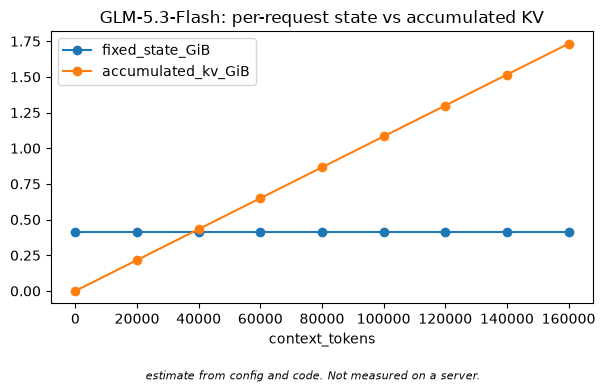

In [5]:
comparison = glm_context_comparison(range(0, 160_001, 20_000), mamba_cache_mode="align", prefill_checkpoint_blocks=1)
rows = [{"context_tokens": r["context_tokens"], "fixed_state_GiB": r["fixed_state_bytes"] / GIB,
         "accumulated_kv_GiB": r["accumulated_kv_bytes"] / GIB} for r in comparison["rows"]]
print("둘이 같아지는 문맥 길이(token):", round(comparison["crossover_tokens"]), "/ kind:", comparison["kind"])


def crossover_row(row):
    """rank 하나끼리 나눈다. crossover_padded는 kv_cases 값이고 crossover_unpadded는 record 합으로 나눈 수업의 계산이다."""
    unpadded_per_rank = row["fixed_bytes_unpadded_all_ranks"] / row["tp_ranks"]
    return {"kind": row["kind"], "tp_ranks": row["tp_ranks"], "mode": row["mamba_cache_mode"],
            "checkpoint": row["prefill_checkpoint_blocks"], "fixed_unpadded_per_rank": int(unpadded_per_rank),
            "fixed_padded_per_rank": row["fixed_bytes_padded_per_rank"],
            "crossover_unpadded": round(unpadded_per_rank / PER_TOKEN), "crossover_padded": round(row["crossover_tokens"])}


display(view.table([crossover_row(r) for r in real_kda_table()
                    if r["num_spec"] == 0 and (r["mamba_cache_mode"], r["prefill_checkpoint_blocks"]) in (("none", 0), ("align", 1))]))
view.sweep_chart(rows, "context_tokens", ["fixed_state_GiB", "accumulated_kv_GiB"],
                 note="estimate from config and code. Not measured on a server.",
                 title="GLM-5.3-Flash: per-request state vs accumulated KV")

이 그림은 요청 하나의 값이고 TP와 padding을 세지 않은 식입니다. 두 선이 만나는 문맥 길이는 약 38,089 token이고, 이보다 짧은 요청에서는 쌓인 KV보다 고정 state가 더 큽니다. `MambaSpec`의 고정 state에 문맥 길이가 없다는 것이 이유입니다(`MambaSpec.max_memory_usage_bytes`([kv_cache_interface.py:1076](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/kv_cache_interface.py#L1076)), P7-62).

그림 위의 표는 같은 교차점을 `kv_cases`의 `real_kda_table`로 다시 셉니다. `crossover_padded`는 실제 클래스 호출의 page 크기와 stride로 나눈 값이고, `crossover_unpadded`는 padding 없는 state를 record 합 11,627로 나눈 수업의 계산입니다. `align`과 checkpoint 1이면 TP1에서 38,089와 39,080입니다. `fixed_unpadded_per_rank` 442,859,520이 page에 맞춰 `fixed_padded_per_rank` 454,557,696으로 올라가기 때문입니다. TP4에서는 9,522와 10,332입니다. 표의 값은 rank 하나끼리 나눈 것이고, 호출에서 고정 state는 rank로 나뉘었지만 main record는 rank마다 1,024 byte 그대로였습니다. TP4는 TP 그룹만 값으로 바꾼 호출이고 실제 4-GPU 실행이 아닙니다. 어느 값도 서버에서 잰 것이 아닙니다.

### Hopper BF16과 Blackwell FP8

GLM-5.3-Flash 레시피의 ["Prefill/Decode disaggregation" 절](https://recipes.vllm.ai/zai-org/GLM-5.3-Flash.md)은 Blackwell에서는 `--kv-cache-dtype fp8`을 더할 수 있고, Hopper는 이 모델의 FP8 KV를 지원하지 않아 BF16 KV로 돌려야 한다고 적습니다. 이 문장은 레시피의 것이고, v0.32.0 코드에서 이를 막는 줄은 찾지 못했습니다(P8-50). 오히려 코드에는 SM90용 sparse backend가 `fp8`을 지원 목록에 둡니다(아래 표). 어느 쪽이 실제인지는 서버 없이 정할 수 없으니, Hopper에 FP8을 주면 무슨 일이 일어나는지는 말하지 않겠습니다.

`auto`는 체크포인트의 KV scheme을 먼저 찾고(`resolve_kv_cache_dtype_string`([torch_utils.py:512](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/utils/torch_utils.py#L512)), P4-01), 없으면 model dtype으로 풀립니다(`kv_cache_dtype_str_to_dtype`([torch_utils.py:533](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/utils/torch_utils.py#L533))). 이 체크포인트의 `quantization_config`에는 KV scheme 키가 없고 config의 `dtype`은 `bfloat16`이므로(P4-18), SM90과 SM10x에서 `auto`는 읽기로는 BF16입니다. SM120은 다릅니다. 서버를 띄운다면 시작 로그의 `kv_cache_dtype` 칸(`kv_cache_dtype`([vllm.py:2727](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/vllm.py#L2727)))과 backend 줄을 먼저 봅니다.

`--kv-cache-dtype`이 닿는 곳은 일부입니다.

- main KV: record 크기는 `(head_size + head_size_v) * dtype 크기`입니다(`state_content_size_bytes`([kv_cache_interface.py:549](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/kv_cache_interface.py#L549))). 다만 `_ds_mla` 형식은 별도 크기를 등록합니다(`MLAAttention.get_kv_cache_spec`([mla_attention.py:1365](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/model_executor/layers/attention/mla_attention.py#L1365))). 같은 `fp8`이어도 어느 attention backend가 잡느냐에 따라 record가 다릅니다. 아래 표의 경로는 코드를 읽은 결과이고 서버에서 확인하지 않았습니다. record 값은 backend와 SM 값을 지정한 실제 클래스 호출에서 같게 나왔습니다(다음 셀 출력).
- indexer: 값은 FP8, scale은 FP32로 따로 정해져 있습니다(`Indexer`([attention.py:257](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/glm5next/common/attention.py#L257))).
- KDA state: `kda_state_dtype`의 입력은 model dtype, `mamba_cache_dtype`, `mamba_ssm_cache_dtype`입니다(`get_state_dtype`([kda.py:178](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/glm5next/common/kda.py#L178))).

| GPU 세대 | 코드가 고르는 길 | `fp8`일 때 main record |
|---|---|---|
| SM10x(Blackwell) | 양자화 KV면 FlashInfer가 먼저입니다(`_get_backend_priorities`([cuda.py:100-105](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/platforms/cuda.py#L100))). 표준 fp8 형식을 쓴다고 로그를 남깁니다(`MLAAttention`([mla_attention.py:541](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/model_executor/layers/attention/mla_attention.py#L541))) | 512 byte |
| SM90(Hopper) | `head_size`가 512면 `FLASHINFER_MLA_SPARSE_SM90`이 먼저이고(`_get_backend_priorities`([cuda.py:143-144](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/platforms/cuda.py#L143))), 지원 목록에 `fp8`이 있으며(`supported_kv_cache_dtypes`([flashinfer_mla_sparse_sm90.py:148-153](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/attention/backends/mla/flashinfer_mla_sparse_sm90.py#L148))), FlashInfer 0.6.18 이상을 요구합니다(`supports_combination`([flashinfer_mla_sparse_sm90.py:205-209](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/attention/backends/mla/flashinfer_mla_sparse_sm90.py#L205))). 레시피의 "지원하지 않음"과 다릅니다 | 512 byte, 레시피와 어긋남 |
| SM120 | `auto`와 `fp8`을 모두 `fp8_ds_mla`로 바꿉니다(`_canonicalize_sparse_mla_kv_cache_dtype`([mla_attention.py:369-374](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/model_executor/layers/attention/mla_attention.py#L369))). 지원 목록에 `bfloat16`이 없습니다(`supported_kv_cache_dtypes`([flashinfer_mla_sparse.py:172-177](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/attention/backends/mla/flashinfer_mla_sparse.py#L172))) | 656 byte |
| SM90에서 `fp8_ds_mla`를 직접 줌 | `FLASHMLA_SPARSE`가 RoPE 칸을 0으로 채운 576 배치로 받습니다(`supports_combination`([flashmla_sparse.py:220-227](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/attention/backends/mla/flashmla_sparse.py#L220))) | 656 byte |

**먼저 예측하세요.** 같은 KV pool에서 main KV record만 1,024 byte에서 512 byte로 줄면 `with_state` 동시성은 문맥 2,048, 128,000, 1,048,576에서 각각 몇 배가 될까요? 2배에 가장 가까운 문맥은 어디입니까? 답을 적은 뒤 실행하세요.

In [6]:
glm_kv = global_kv_per_token(GLM)
SPARSE_LAYERS = len(glm_kv["parts"][0]["layers"])


def per_token_with_main_record(record):
    """main record만 바꾸고 indexer 몫은 그대로 둔다. 수업의 계산이고 제작사 값이 아니다."""
    return record * SPARSE_LAYERS + glm_kv["indexer_bytes_per_token"]


def dtype_row(context):
    def requests(record):
        return base["kv_bytes"] / (STATE["fixed_bytes_per_request"] + context * per_token_with_main_record(record))

    bf16, plain, ds_mla = requests(1024), requests(512), requests(656)
    return {"context_tokens": context, "record_1024": round(bf16, 1), "record_512": round(plain, 1), "gain_512": round(plain / bf16, 2),
            "record_656": round(ds_mla, 1), "gain_656": round(ds_mla / bf16, 2)}


print("token당 byte / kind: estimate")
for record in (1024, 512, 656):
    print(" main record", record, ":", per_token_with_main_record(record))
REAL_DTYPES = ("glm.flashmla.bf16", "glm.flashinfer_sm90.fp8", "glm.flashinfer_sm100.fp8", "glm.flashmla.fp8_ds_mla",
               "glm.flashinfer_sm120.auto")
display(view.table([r for r in real_scenarios(GLM) if r["scenario"] in REAL_DTYPES],
                   ["kind", "scenario", "cache_dtype", "main_record_bytes", "block_size", "stride_bytes_per_token"]))
view.table([dtype_row(c) for c in (2_048, 128_000, 1_048_576)])

token당 byte / kind: estimate
 main record 1024 : 11627.0
 main record 512 : 5995.0
 main record 656 : 7579.0


,kind,scenario,cache_dtype,main_record_bytes,block_size,stride_bytes_per_token
0,real_class,glm.flashmla.bf16,auto,1024,4352,11631.529412
1,real_class,glm.flashmla.fp8_ds_mla,fp8_ds_mla,656,8576,7592.955224
2,real_class,glm.flashinfer_sm90.fp8,fp8,512,8576,5995.164179
3,real_class,glm.flashinfer_sm100.fp8,fp8,512,8576,6052.298507
4,real_class,glm.flashinfer_sm120.auto,fp8_ds_mla,656,8704,7640.470588


,context_tokens,record_1024,record_512,gain_512,record_656,gain_656
0,2048,308.3,316.1,1.03,313.9,1.02
1,128000,74.5,118.9,1.60,101.8,1.37
2,1048576,11.4,21.4,1.88,17.1,1.51


**관찰할 것.** 맨 아래 표의 `gain_512` 칸을 문맥 길이 순서로 읽으세요. 출력 위쪽의 token당 byte 비와 비교해 어디서 벌어집니까? `gain_656`은 어떻습니까?

record가 512 byte면 token당 byte는 11,627에서 5,995로 줄어 비가 1.94이고, indexer 몫 때문에 정확히 2가 아닙니다. 동시성의 이득은 문맥 2,048에서 1.03배, 1,048,576에서 1.88배입니다. 656 byte 배치면 token당 7,579 byte이고 1,048,576에서 1.51배입니다. FP8 KV가 줄이는 것은 KV block의 원시 payload입니다. activation과 CUDA graph 몫은 이 식에 없을 뿐이고, KV dtype이 그 값을 바꾸지 않는다고 코드로 확인하지는 않았습니다. 그래서 전체 메모리 절감 비율은 이 자료만으로 계산할 수 없습니다(P4-10). 이 값들은 수업의 계산이고 레시피나 제작사가 낸 값이 아닙니다.

가운데 표는 `real_class` 값입니다. `fp8`의 record 512 byte는 block이 8576이고 `stride_bytes_per_token`이 5,995.16(SM90 지정)과 6,052.30(SM100 지정)입니다. BF16 TP1의 block 4352와 다릅니다. 맨 아래 표는 record만 바꾼 계산이라 이 block 변화와 page 차이를 넣지 않았습니다. 이 호출은 어느 GPU에서 어느 backend가 잡히는지를 말하지 못합니다. 정확도 영향도 이 표에 없습니다. SM120에는 위 표대로 `record_1024` 칸이 해당하지 않습니다.

**수업의 권장.** Hopper에서는 레시피대로 BF16 KV로 시작합니다. FP8을 시험한다면 시작 로그의 `kv_cache_dtype`과 `Using ... KV cache format`([mla_attention.py:530](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/model_executor/layers/attention/mla_attention.py#L530)), 고른 backend를 먼저 기록하고, 정확도를 따로 잽니다.

가중치는 별도 축입니다. BF16 체크포인트는 가중치 메모리가 약 2배라고 레시피가 적습니다(P4-19). 레시피의 AMD 절이 적은 KV pool 비교 수치는 체크포인트(가중치)를 바꾼 비교이고 두 경우의 KV dtype을 레시피가 적지 않았습니다. H200 값도 아니고 측정 방법은 미확인입니다(P4-11). 다음 셀은 그 2배를 이 가상의 장비에 넣어 봅니다.

In [7]:
# 실패 재현: BF16 체크포인트의 가중치(약 2배)가 가상 장비의 예산을 넘는 경우
try:
    capacity_estimate(GLM, gpu_total_bytes=500 * GIB, weights_bytes=2 * 306 * GIB, other_bytes=20 * GIB, block_size=BLOCK)
except ValueError as error:
    print(type(error).__name__, ":", error)

ValueError : KV 예산이 -184683593728 byte입니다: budget=493921239040 - weights=657129996288 - other=21474836480


**관찰할 것.** 메시지의 `budget`, `weights`, `other` 값을 읽고 어느 항이 예산을 넘겼는지 찾으세요. 이 오류는 수업용 계산이 내는 것이고 vLLM의 메시지가 아닙니다. 실제 서버가 이 상황에서 무엇을 출력하는지는 확인하지 않았습니다.

V4.1도 같은 질문이 있습니다. main record가 GPU 세대에 따라 달라서, DeepSeek-V4.1의 FlashInfer 경로는 SM10x에서 `fp8_ds_mla`를 거부하고 SM120에서는 `fp8`, `fp8_e4m3`, `fp8_ds_mla`만 받습니다(P8-50). LMCache 레시피는 SM100의 record를 528 byte, 나머지를 584 byte로 적습니다(P8-48, 저장 key에 이 구분이 들어가는지는 미확인). 아래 셀은 record 크기만 바꿔 token당 byte를 다시 셉니다. 이 값들은 수업의 계산이고 제작사 값이 아니며, SWA 캐시는 세지 않았습니다. 논문의 890과 맞는 것은 첫 행뿐입니다.

In [8]:
def v41_per_token(main_record, indexer_record):
    """층 묶음은 kv_cases에서 가져오고 record 크기만 바꾼다. 수업의 계산이다."""
    total = 0.0
    for part in global_kv_per_token(V41)["parts"]:
        record = main_record if part["cache"] == "main" else indexer_record
        total += record * len(part["layers"]) / part["tokens_per_state"]
    return total


view.table([{"main_record": m, "indexer_record": i, "bytes_per_token": v41_per_token(m, i), "note": note}
            for m, i, note in ((288, 68, "paper format, nvfp4_ds_mla and mxfp4 indexer"),
                               (528, 132, "SM100 record, indexer auto"),
                               (584, 132, "other GPUs record, indexer auto"))])

,main_record,indexer_record,bytes_per_token,note
0,288,68,890.0,"paper format, nvfp4_ds_mla and mxfp4 indexer"
1,528,132,1650.0,"SM100 record, indexer auto"
2,584,132,1790.0,"other GPUs record, indexer auto"


### MTP draft가 KDA state를 바꾸는 방식

레시피의 TP4 명령은 `--speculative-config '{"method":"mtp","num_speculative_tokens":5}'`를 줍니다. `02b`에서 본 대로 MTP의 draft 자리는 0입니다. 이 자리는 `token_budget`이 아니라 `input_budget`에서 뺍니다(`draft_slots`([scheduler.py:613](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L613)), `input_budget` 차감([scheduler.py:857](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L857)), P2-57). 그렇다고 메모리 영향이 없는 것은 아닙니다.

**먼저 예측하세요.** `num_speculative_tokens`를 0에서 5로 바꾸면 아래 표의 `conv_bytes_per_state`, `recurrent_bytes_per_state`, `resident_states`, `fixed_bytes_per_request` 중 어느 칸이 그대로일까요? `fixed_bytes_per_request`는 대략 몇 배가 될까요? 답을 적은 뒤 실행하세요.

In [9]:
def state_row(num_spec, mode, checkpoint):
    state = glm_kda_fixed_state(num_spec=num_spec, mamba_cache_mode=mode, prefill_checkpoint_blocks=checkpoint)
    crossover = glm_context_comparison([0], num_spec=num_spec, mamba_cache_mode=mode,
                                       prefill_checkpoint_blocks=checkpoint)["crossover_tokens"]
    return {"num_spec": num_spec, "mode": mode, "checkpoint": checkpoint,
            **{k: state[k] for k in ("conv_bytes_per_state", "recurrent_bytes_per_state", "resident_states",
                                     "fixed_bytes_per_request")},
            "crossover_tokens": round(crossover)}


display(view.table([state_row(0, "none", 0), state_row(0, "align", 1), state_row(1, "align", 1), state_row(5, "align", 1)]))
for line in STATE["assumptions"]:
    print(" -", line)

,num_spec,mode,checkpoint,conv_bytes_per_state,recurrent_bytes_per_state,resident_states,fixed_bytes_per_request,crossover_tokens
0,0,none,0,147456,4194304,1,147619840,12696
1,0,align,1,147456,4194304,3,442859520,38089
2,1,align,1,196608,4194304,4,597164032,51360
3,5,align,1,393216,4194304,8,1247805440,107320


 - mamba_cache_mode none의 state 1벌이 하한이다. prefix caching을 켜면 align으로 바뀌어 더 많이 잡는다(P8-23, P8-24).
 - conv state는 BF16(model dtype), recurrent state는 float32다. 둘 다 dtype 설정이 auto일 때다. vllm/model_executor/layers/mamba/mamba_utils.py:139-141
 - TP 샤딩과 page_size_padded는 계산하지 않았다. 실제 클래스 호출 값은 real_kda_table에 있다. vllm/v1/kv_cache_interface.py:1063-1070
 - sparse MLA 층마다 tail ring(CircularBufferSpec)이 요청당 더 있지만 세지 않았다. vllm/models/glm5next/common/attention.py:156-177, :271
 - 측정이 아니라 코드 식에 config 값을 넣은 추정이다. GLM-5.3-Flash 전용 보고서는 찾지 못했다(P7-48).
 - KDA라는 이름은 config의 kda_layers와 vLLM의 kda.py에서 왔다. Z.ai 문서가 이 이름을 쓰는지는 확인하지 못했다(P7-44).


**관찰할 것.** `none` 행은 prefix caching이 꺼진 경우의 하한이고 나머지 행은 켜졌을 때입니다. 두 번째 행과 네 번째 행의 `resident_states`와 `crossover_tokens`를 비교하세요.

draft가 닿는 곳이 둘입니다. `conv_bytes_per_state`는 conv 길이가 `kernel - 1 + num_spec`이어서 늘고(`kda_state_shape`([mamba_utils.py:324](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/model_executor/layers/mamba/mamba_utils.py#L324))), `resident_states`는 층마다 state block이 `2 + 추측 block + checkpoint block`이어서 늘어납니다(`MambaSpec.max_memory_usage_bytes`([kv_cache_interface.py:1079](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/kv_cache_interface.py#L1079))). 추측 block 수는 `num_speculative_tokens` 그대로입니다(`get_kv_cache_spec`([abstract.py:82](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/model_executor/layers/mamba/abstract.py#L82))). 표에서 `recurrent_bytes_per_state`만 그대로이고, 요청당 값은 442,859,520에서 1,247,805,440 byte로 2.82배가 되고, 두 선이 만나는 문맥은 약 107,320 token으로 밀립니다.

checkpoint 1은 FlashKDA가 선택됐을 때입니다. 선택 조건은 CUDA SM90, SM10x, SM12x, bfloat16, `head_dim` 128, 하한이 있는 gate이고(`_resolve_kda_prefill_backend`([kda.py:137-154](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/glm5next/common/kda.py#L137))), Triton이면 checkpoint block이 없습니다(P8-24). 세지 않은 것도 있습니다. tail ring 폭도 draft 수를 따라 늘고(`index_kpool + num_speculative_tokens`를 kpool의 2 거듭제곱 배로 올린 값이라 config의 kpool 4에 draft 5면 16입니다), block 크기는 이 ring의 배수여야 합니다(`Glm5NextTailCache.get_kv_cache_spec`([attention.py:162-163](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/glm5next/common/attention.py#L162)), P7-43).

표의 byte 값은 config에 코드 식을 넣은 수업의 추정입니다. GLM-5.3-Flash 전용 보고서는 찾지 못했습니다(P7-48, 미확인). 실제 클래스 호출(`real_kda_table`)의 padding 없는 합도 같은 442,859,520과 1,247,805,440입니다. page까지 넣으면 draft 0은 454,557,696이고, draft 5는 block이 4480으로 올라 padding이 사라져 1,247,805,440 그대로입니다(`docs/reference/specs.md`). 서버에서 잰 값은 아닙니다.

**왜 이렇게 설계했나.** 코드 주석은 draft를 검증할 때 conv 창을 할당 폭 밖까지 읽지 않고 밀기 위해 conv 폭에 `num_spec`을 포함한다고 적습니다(`get_state_shape`([kda.py:192](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/glm5next/common/kda.py#L192))).

## 3. 결정 순서와 증상표

아래 순서는 **수업의 권장**입니다. vLLM이 정한 절차가 아닙니다. 앞의 결정이 뒤의 선택지를 바꾸므로 위에서 아래로 정하자는 제안입니다. 오른쪽 두 칸은 코드와 문서를 읽은 사실입니다.

| 순서 | 정할 것 | 뒤 결정에 미치는 영향 | 근거 |
|---:|---|---|---|
| 1 | KV dtype과 GPU 세대 | token당 byte와 고를 수 있는 dtype을 정합니다. H200(Hopper)의 FP8 KV는 레시피와 코드가 어긋납니다. 레시피는 지원하지 않으니 BF16으로 돌리라 적고, 코드에는 막는 줄이 없고 SM90 backend의 지원 목록에 `fp8`이 있습니다. 서버 없이 가릴 수 없으니 수업의 권장은 레시피를 따릅니다(2절). 세대가 다르면 cache를 공유하면 안 된다고 LMCache가 적습니다 | P8-48(미확인), P8-50 |
| 2 | prefix caching | Mamba 계열은 켜져 있어야 `align`으로 전환되고, 꺼 두면 LMCache가 시작을 거부합니다. 끄는 것은 GLM-5.2 레시피의 선택이지 일반 규칙이 아닙니다 | P8-24, P8-29 |
| 3 | hybrid KV cache manager(코드와 오류 문구의 줄임말이 HMA입니다) | connector가 지원하는지로 갈립니다. KDA 모델은 끌 수 없습니다 | P8-14, P8-15 |
| 4 | block 크기 | 기본 16에서 hybrid와 kernel 요구에 따라 커지고, chunk 크기가 여기에 묶입니다. GLM-5.3-Flash의 실제 클래스 호출 값은 BF16 TP1 4352, TP4 1152이지만 GPU 값이 아니므로 시작 로그에서 읽습니다 | P8-09, P8-20, P8-51 |
| 5 | speculative 설정 | 2절에서 본 KDA state와 tail ring을 늘립니다. draft 자리는 `input_budget`에서 빼고 MTP는 0입니다 | P2-57, P8-23 |
| 6 | `cache_salt` | 격리 단위입니다. 11절에서 다룹니다 | P5-09, P8-45 |

**요청마다 바꿀 수 없는 것.** 위 1번부터 5번까지는 서버 시작 값입니다. `--kv-cache-dtype`, `--block-size`, `--[no-]enable-prefix-caching`, `--mamba-cache-mode`, `--[no-]disable-hybrid-kv-cache-manager`, `--speculative-config`, `--kv-transfer-config`(그 안의 `kv_load_failure_policy` 포함)가 그렇습니다. 요청 스키마 `ChatCompletionRequest`([protocol.py:220](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/openai/chat_completion/protocol.py#L220))와 `SamplingParams`([sampling_params.py:268](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/sampling_params.py#L268))의 파일에서 이 설정들의 필드를 grep으로 찾지 못했습니다. 요청에 실리는 것은 `cache_salt`([protocol.py:485](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/openai/chat_completion/protocol.py#L485)), `kv_transfer_params`([protocol.py:499](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/entrypoints/openai/chat_completion/protocol.py#L499)), `SamplingParams`의 `skip_reading_prefix_cache`([sampling_params.py:423](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/sampling_params.py#L423))입니다.

### 증상에서 지표로

아래 표의 증상과 지표의 대응은 코드와 문서를 읽은 결과이고, 서버에서 증상을 관찰해 만든 표가 아닙니다. "먼저 할 일" 칸은 **수업의 권장**입니다.

| 증상 | 볼 지표나 로그 | 먼저 할 일(수업의 권장) | 근거 |
|---|---|---|---|
| 부하가 오르면 요청이 되돌아가 다시 계산한다 | `vllm:num_preemptions`, `vllm:kv_cache_usage_perc` | `--gpu-memory-utilization` 상향, `max_num_seqs`나 `max_num_batched_tokens` 축소, TP나 PP 증가. GLM-5.3-Flash면 2절의 요청당 state를 다시 계산 | P3-25, P8-49 |
| 같은 prompt를 다시 보내도 로컬 hit이 낮다 | `vllm:prefix_cache_queries`, `vllm:prefix_cache_hits` | system prompt와 tool 목록(순서 포함)이 요청마다 바뀌는지, `cache_salt`가 바뀌는지 확인. 달라진 token이 든 block부터 재사용이 끊기고 그 앞 block은 남습니다. GLM-5.3-Flash 템플릿은 tool 정의를 system 메시지보다 앞에 놓으므로 tool 변경이 더 앞에서 끊습니다 | P5-08, P8-35, P8-45 |
| 외부 hit이 낮다 | `vllm:external_prefix_cache_queries`, `vllm:external_prefix_cache_hits` | 온전한 chunk만 저장되는지와 생성 token 저장이 꺼져 있는지 확인, 서버의 `lmcache_mp.l1_evicted` 확인 | P8-09, P8-12, P8-35, P8-36 |
| 어느 계층에서 왔는지 모르겠다 | `vllm:prompt_tokens_cached_by_source`, 내장은 `vllm:kv_offload_*`, LMCache는 서버 OTel 지표 | LMCache hit은 `external_unspecified`로만 잡히므로 서버 쪽에서 본다 | P8-35, P8-36 |
| 요청이 오류로 끝난다 | `vllm:request_success`의 `finished_reason`이 `error`, 서버 쪽 `KEY_NOT_READABLE` | 8절의 정책 확인, 큐가 깊으면 `--l1-read-ttl-seconds`와 `--session-ttl-seconds` 상향 | P8-33, P8-52 |
| 시작이 `Failed to promote local KV cache specs`로 멈춘다 | 시작 로그 | HMA가 꺼졌습니다. HMA를 지원하는 connector를 고릅니다 | P8-15 |
| 시작이 `got an unexpected keyword argument 'bounded_replay'`(`TypeError`)로 멈춘다 | 시작 로그 | HMA가 꺼진 채 `SlidingWindowMLASpec`을 승격하다 난 오류입니다. HMA를 지원하는 connector를 고르고 `--disable-hybrid-kv-cache-manager`를 뺍니다 | P8-15 |
| 시작이 `does not support HMA but HMA is enabled`로 멈춘다 | 시작 로그 | 명시적 HMA 켬과 connector가 맞지 않습니다 | P8-14 |
| 시작이 `LMCache cannot serve this model's KV cache groups`로 멈춘다 | 시작 로그 | Mamba 모델이면 `--no-enable-prefix-caching`을 뺍니다 | P8-29 |
| 시작이 `must be a multiple of`로 멈춘다(`LMCache chunk size`로 시작하거나 뒤가 `group`) | 시작 로그의 `group_tokens_per_block`, `scheduler_block_size` | 서버 `--chunk-size`를 그 배수로 맞춥니다 | P8-09 |
| 시작이 `require max_num_batched_tokens >= block_size`로 멈춘다 | 시작 로그 | `--max-num-batched-tokens`를 통합 block 크기 이상으로 올립니다 | P8-19 |

문구의 출처는 `_promote_local_kv_cache_specs`([kv_cache_utils.py:1760](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_utils.py#L1760)), `create_connector`([factory.py:58](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/distributed/kv_transfer/kv_connector/factory.py#L58)), `validate_kv_cache_groups`([kv_cache_group_edits.py:169](https://github.com/LMCache/LMCache/blob/3e11e10812b448142c6cdb177a3058652bd826fa/lmcache/integration/vllm/kv_cache_group_edits.py#L169)), `vllm_block_size` 검사([vllm_multi_process_adapter.py:780](https://github.com/LMCache/LMCache/blob/3e11e10812b448142c6cdb177a3058652bd826fa/lmcache/integration/vllm/vllm_multi_process_adapter.py#L780)), `LMCacheMPConnector`([lmcache_mp_connector.py:817-818](https://github.com/LMCache/LMCache/blob/3e11e10812b448142c6cdb177a3058652bd826fa/lmcache/integration/vllm/lmcache_mp_connector.py#L817)), `validate_mamba_step_alignment`([lmcache_mp_connector.py:422-424](https://github.com/LMCache/LMCache/blob/3e11e10812b448142c6cdb177a3058652bd826fa/lmcache/integration/vllm/lmcache_mp_connector.py#L422))입니다. 시작 오류 대부분은 7절에서 실제 클래스 호출 결과로 다시 봅니다. Counter는 Prometheus 출력에서 `_total`이 붙습니다. 표의 `vllm:num_preemptions`는 출력에서 `vllm:num_preemptions_total`입니다. prometheus_client 0.26.0으로 같은 이름의 Counter를 만들어 확인했고 vLLM 서버의 출력은 아닙니다(P3-38).

## 4. 내장 prefix cache의 한계와 CPU, 디스크 계층

내장 prefix cache는 이 vLLM 인스턴스의 GPU block 안에서만 재사용합니다(P8-07). DP rank마다 KV cache가 따로라고 문서가 적고(P3-17, DP 내부 코드는 따라가지 않아 미확인), `02b`에서 본 대로 hash가 있는 block도 새 요청이 받아 가면 사라집니다. 턴 사이에 다른 요청이 그 block을 받아 가면 다음 턴은 그 부분을 다시 계산합니다. Kimi K3 보고서는 1M 문맥에서 이런 miss의 비용이 크다는 이유로 쉬고 있는 prefix를 CPU DRAM의 외부 풀에 두었다고 적습니다(P7-54, 제작사 주장).

그럼 계층을 더하면 항상 나아질까요? 이것은 vLLM도 LMCache도 아닌 수업용 모델 `tier_sim`으로 봅니다. 요청을 하나씩 처리하며 hit이 어느 계층에서 왔는지 세고, 시간은 수업이 정한 toy 값으로만 셉니다. 모델링하지 않은 것은 아래 셀이 출력합니다. 출력의 "층"은 저장 계층(GPU, CPU, 디스크)을 뜻합니다.

부하는 `05`에서 다룰 에이전트의 모양입니다. 세션 넷이 같은 앞부분을 쓰고, 턴마다 대화가 자라고, 세션을 번갈아 돕니다.

In [10]:
for line in NOT_MODELED:
    print(" -", line)

REQS = agent_workload(sessions=4, turns=3, shared_prefix_tokens=16, tokens_per_turn=16)
TIER_BLOCK = 4  # 수업이 정한 작은 값. block 하나가 4 token이다.
print("\n요청", len(REQS), "개, prompt token 합", sum(len(r.tokens) for r in REQS), ", 가장 긴 요청", max(len(r.tokens) for r in REQS), "token")
view.table([{"request_id": r.request_id, "prompt_tokens": len(r.tokens)} for r in REQS[:5]])

 - 실제 지연과 대역폭은 없다. toy_* 상수는 층의 순서만 보이려고 고른 값이고 어떤 하드웨어의 측정값도 아니다.
 - 실제 KV 값과 record 크기는 없다. block 하나는 어느 층에서나 같은 한 칸이다. 크기 계산은 kv_cases를 본다.
 - 동시 실행, 비동기 load, 전송 대기(WAITING_FOR_REMOTE_KVS)는 없다. 요청은 하나씩 끝까지 처리한다(P8-31).
 - LMCache의 저장 시점과 조회 절차는 따르지 않는다. 밀려날 때 아래 층으로 옮기는 write-back 하나만 있다(P7-54, P8-25).
 - load 실패와 kv_load_failure_policy는 없다. 층에 있으면 항상 읽힌다(P8-33).
 - sliding window와 scratch group은 없다. SWA 재생 비용과 저장하지 않는 group은 세지 않는다(P8-18, P8-32).
 - group별 block 크기와 lcm 정렬은 없다. 층 전체가 block_tokens 하나를 쓴다(P8-20, P8-21).
 - KDA 상태는 경계 block과 수명이 같다고 놓았다. 상태 자체의 크기와 따로 일어나는 축출은 없다(P7-53, P7-54).
 - FlashKDA checkpoint block을 LMCache가 저장하는 방식은 확인하지 못해 넣지 않았다(P8-26).
 - align 모드의 '스텝 끝이 block 경계일 때만 저장'은 없다. 계산을 지나간 경계에는 모두 상태가 있다고 놓았다(P8-23).
 - 경계로 내려 버린 block을 읽는 비용은 세지 않는다.
 - 실행 중인 요청의 block 고정(ref count)은 없다. 대신 요청 하나의 block이 GPU 층보다 많으면 거부한다.
 - cache salt와 요청 사이 격리는 없다. token이 같으면 같은 block이다.

요청 12 개, prompt token 합 576 , 가장 긴 요청 64 token


,request_id,prompt_tokens
0,s0-t1,32
1,s1-t1,32
2,s2-t1,32
3,s3-t1,32
4,s0-t2,48


**먼저 예측하세요.** 아래 네 구성을 돌립니다. GPU 16 block만, CPU 40 block 추가, CPU 8과 디스크 80 block 추가, 그리고 같은 구성에서 디스크를 끈 것입니다. `gpu_hit_blocks`, `cpu_hit_blocks`, `disk_hit_blocks`, `recomputed_tokens` 중 네 행에서 값이 변하지 않을 칸은 무엇일까요? CPU 40과 CPU 8 + 디스크 80의 `recomputed_tokens`는 어느 쪽이 작을까요? 답을 적은 뒤 실행하세요.

In [11]:
TOTAL_COLUMNS = ("gpu_hit_blocks", "cpu_hit_blocks", "disk_hit_blocks", "hit_tokens", "recomputed_tokens",
                 "dropped_blocks", "toy_ms")


def tier_row(setup, requests=REQS, **kwargs):
    result = simulate_tiers(requests, block_tokens=TIER_BLOCK, **kwargs)
    return {"setup": setup, "enabled_tiers": "+".join(result["enabled_tiers"]),
            **{k: result["totals"][k] for k in TOTAL_COLUMNS}}


TIER_SETUPS = {"gpu only": dict(gpu_blocks=16),
               "cpu 40": dict(gpu_blocks=16, cpu_blocks=40),
               "cpu 8 + disk 80": dict(gpu_blocks=16, cpu_blocks=8, disk_blocks=80),
               "cpu 8, disk off": dict(gpu_blocks=16, cpu_blocks=8, disk_blocks=80, disabled_tiers=["disk"])}
print(simulate_tiers(REQS, gpu_blocks=16)["note"])
view.table([tier_row(name, **kwargs) for name, kwargs in TIER_SETUPS.items()])

toy 비용의 결과이고 측정이 아니다. 실제 지연으로 인용하지 않는다.


,setup,enabled_tiers,gpu_hit_blocks,cpu_hit_blocks,disk_hit_blocks,hit_tokens,recomputed_tokens,dropped_blocks,toy_ms
0,gpu only,gpu,44,0,0,176,400,84,400.0
1,cpu 40,gpu+cpu,44,48,0,368,208,0,256.0
2,cpu 8 + disk 80,gpu+cpu+disk,44,8,40,368,208,0,376.0
3,"cpu 8, disk off",gpu+cpu,44,8,0,208,368,68,376.0


**관찰할 것.** `gpu_hit_blocks` 칸과 `dropped_blocks` 칸을 함께 읽고, `recomputed_tokens`가 같은 두 행의 `toy_ms`를 비교하세요.

`gpu_hit_blocks`는 네 행 모두 44입니다. 이 모델에서 아래 계층은 GPU가 잡던 것을 빼앗지 않고, 밀려나 사라지던 block을 받아 둘 뿐입니다. GPU만 있으면 `dropped_blocks`가 84이고 다시 계산하는 token이 400입니다. CPU 40이면 0과 208입니다. CPU 8 + 디스크 80도 208로 같지만 `disk_hit_blocks`가 40이어서 `toy_ms`는 256이 아니라 376입니다. 디스크를 끄면 그 40 block이 사라져 368 token을 다시 계산합니다.

`toy_ms`는 수업이 정한 상수의 결과입니다. 측정이 아니고 실제 지연으로 인용하면 안 됩니다. 방향만 봅니다.

다음 셀은 GPU 크기를 바꿉니다. GPU가 충분히 크면 CPU 계층이 할 일이 있을까요?

,gpu_blocks,cpu_hit_blocks,recomputed_blocks_with_cpu,recomputed_blocks_gpu_only
0,16,48,52,100
1,24,40,52,92
2,32,28,52,84
3,40,12,52,68
4,48,0,52,52
5,64,0,52,52
6,96,0,52,52


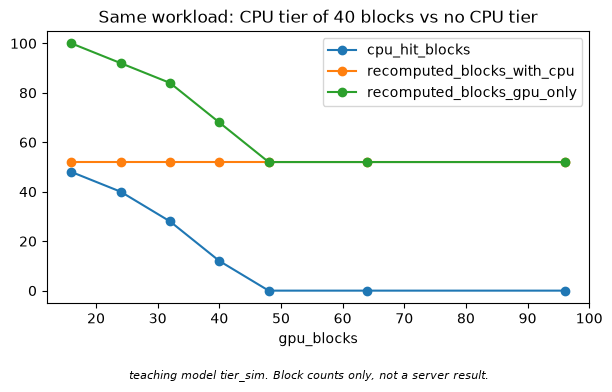

In [12]:
gpu_sweep = []
for gpu_blocks in (16, 24, 32, 40, 48, 64, 96):
    with_cpu = tier_row("with cpu", gpu_blocks=gpu_blocks, cpu_blocks=40)
    gpu_only = tier_row("gpu only", gpu_blocks=gpu_blocks)
    gpu_sweep.append({"gpu_blocks": gpu_blocks, "cpu_hit_blocks": with_cpu["cpu_hit_blocks"],
                      "recomputed_blocks_with_cpu": with_cpu["recomputed_tokens"] // TIER_BLOCK,
                      "recomputed_blocks_gpu_only": gpu_only["recomputed_tokens"] // TIER_BLOCK})
display(view.table(gpu_sweep))
view.sweep_chart(gpu_sweep, "gpu_blocks", ["cpu_hit_blocks", "recomputed_blocks_with_cpu", "recomputed_blocks_gpu_only"],
                 note="teaching model tier_sim. Block counts only, not a server result.",
                 title="Same workload: CPU tier of 40 blocks vs no CPU tier")

**관찰할 것.** `cpu_hit_blocks`가 0이 되는 `gpu_blocks`를 찾고, 그 행에서 `recomputed_blocks_with_cpu`와 `recomputed_blocks_gpu_only`를 비교하세요.

GPU 16 block에서 `recomputed_blocks_gpu_only`는 100이고 CPU가 있으면 52입니다. GPU 48 block부터는 `cpu_hit_blocks`가 0이고 두 칸이 52로 같습니다. 밀려나는 일이 없으면 아래 계층은 쓰이지 않습니다. 52 block은 처음 보는 내용이라 어떤 구성으로도 줄지 않습니다. 반대로 재사용 자체가 없는 부하도 있습니다. 다음 셀의 부하는 세션마다 앞부분이 다르고 턴이 하나입니다.

In [13]:
NO_REUSE = agent_workload(sessions=8, turns=1, shared_prefix_tokens=0, tokens_per_turn=64)
view.table([tier_row("no reuse, gpu only", requests=NO_REUSE, gpu_blocks=16),
            tier_row("no reuse, cpu 40", requests=NO_REUSE, gpu_blocks=16, cpu_blocks=40)])

,setup,enabled_tiers,gpu_hit_blocks,cpu_hit_blocks,disk_hit_blocks,hit_tokens,recomputed_tokens,dropped_blocks,toy_ms
0,"no reuse, gpu only",gpu,0,0,0,0,512,112,512.0
1,"no reuse, cpu 40",gpu+cpu,0,0,0,0,512,72,512.0


두 행의 `hit_tokens`가 같습니다. 이 부하에서 계층은 저장만 하고 돌려받지 못합니다. 쓰기 비용은 이 모델에 없으므로 실제로는 손해가 더 커질 수 있습니다. 이 마지막 문장은 수업의 해석입니다.

마지막으로 계층을 읽는 비용입니다. 다음 셀은 디스크의 toy 비용만 바꿉니다.

,toy_disk_ms_per_block,disk_on_toy_ms,disk_off_toy_ms
0,1,256.0,376.0
1,2,296.0,376.0
2,4,376.0,376.0
3,8,536.0,376.0
4,16,856.0,376.0


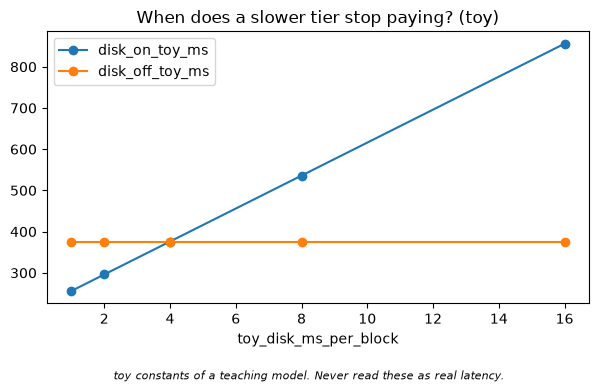

In [14]:
def disk_cost_row(disk_ms):
    costs = ToyCosts(toy_disk_ms_per_block=float(disk_ms))
    kwargs = dict(block_tokens=TIER_BLOCK, gpu_blocks=16, cpu_blocks=8, toy_costs=costs)
    on = simulate_tiers(REQS, disk_blocks=80, **kwargs)["totals"]["toy_ms"]
    off = simulate_tiers(REQS, **kwargs)["totals"]["toy_ms"]
    return {"toy_disk_ms_per_block": disk_ms, "disk_on_toy_ms": on, "disk_off_toy_ms": off}


disk_costs = [disk_cost_row(ms) for ms in (1, 2, 4, 8, 16)]
display(view.table(disk_costs))
view.sweep_chart(disk_costs, "toy_disk_ms_per_block", ["disk_on_toy_ms", "disk_off_toy_ms"],
                 note="toy constants of a teaching model. Never read these as real latency.",
                 title="When does a slower tier stop paying? (toy)")

**관찰할 것.** 두 선이 만나는 `toy_disk_ms_per_block`을 읽고, `TIER_BLOCK`과 toy 재계산 비용(token당 1 toy ms)으로 그 값을 설명해 보세요.

**수업의 해석.** 계층에서 읽는 비용이 그 block을 다시 계산하는 비용보다 작을 때만 그 계층은 이깁니다. 이 부등식만 가져가고 숫자는 버리세요. 위 숫자는 toy 상수이고, 실제 읽기 비용과 재계산 비용은 자기 하드웨어에서 재야 합니다. 실제 시스템의 쓰기 비용과 전송 대기는 이 모델에 없습니다.

### KDA 경계 규칙

지금까지는 찾은 block을 전부 쓸 수 있다고 놓았습니다. KDA 층이 있는 hybrid 모델은 다릅니다. `state_checkpoint_blocks`는 상태가 저장된 경계의 간격을 뜻하는 수업용 입력입니다. 3이면 KV block이 더 있어도 hit은 3 block 배수에서 끝납니다. 3이라는 값은 수업이 정했고 vLLM의 실제 간격이 아닙니다.

**먼저 예측하세요.** CPU 40 구성에 `state_checkpoint_blocks=3`을 줍니다. 요청 `s0-t2`는 이 규칙이 없으면 앞 8 block이 hit입니다. 규칙이 있으면 `hit_tokens`와 `discarded_by_checkpoint_tokens`는 각각 얼마가 될까요? 전체 `recomputed_tokens`는 208에서 어느 쪽으로 움직일까요? `cpu_hit_blocks`도 바뀔까요? 답을 적은 뒤 실행하세요.

In [15]:
# 실패 재현: KV hit만 보고 복원 길이를 세면 다시 계산할 token을 적게 잡는다
KDA_COLUMNS = ("gpu_hit_blocks", "cpu_hit_blocks", "hit_tokens", "discarded_by_checkpoint_tokens", "recomputed_tokens", "toy_ms")
kv_only = simulate_tiers(REQS, block_tokens=TIER_BLOCK, gpu_blocks=16, cpu_blocks=40)
with_boundary = simulate_tiers(REQS, block_tokens=TIER_BLOCK, gpu_blocks=16, cpu_blocks=40, state_checkpoint_blocks=3)
display(view.table([{"rule": "KV blocks only (wrong for KDA)", **{k: kv_only["totals"][k] for k in KDA_COLUMNS}},
                    {"rule": "state boundary every 3 blocks", **{k: with_boundary["totals"][k] for k in KDA_COLUMNS}}]))
view.table(with_boundary["rows"][4:8], ["request_id", "prompt_tokens", "gpu_hit_blocks", "cpu_hit_blocks", "hit_tokens",
                                        "discarded_by_checkpoint_tokens", "recomputed_tokens"])

,rule,gpu_hit_blocks,cpu_hit_blocks,hit_tokens,discarded_by_checkpoint_tokens,recomputed_tokens,toy_ms
0,KV blocks only (wrong for KDA),44,48,368,0,208,256.0
1,state boundary every 3 blocks,41,40,324,44,252,292.0


,request_id,prompt_tokens,gpu_hit_blocks,cpu_hit_blocks,hit_tokens,discarded_by_checkpoint_tokens,recomputed_tokens
0,s0-t2,48,4,2,24,8,24
1,s1-t2,48,4,2,24,8,24
2,s2-t2,48,4,2,24,8,24
3,s3-t2,48,4,2,24,8,24


**관찰할 것.** 아래쪽 표에서 `hit_tokens`와 `discarded_by_checkpoint_tokens`를 더해 보고, `gpu_hit_blocks`와 `cpu_hit_blocks`의 합으로 `hit_tokens`를 다시 세어 보세요. 찾은 KV를 왜 버리는지는 7절에서 코드로 봅니다.

위쪽 표 두 행의 차이는 368 대 324이고 버린 token이 44입니다. 쓰는 KV가 줄었으므로 `gpu_hit_blocks`는 44에서 41로, `cpu_hit_blocks`는 48에서 40으로 줄었습니다. 경계로 내려 버린 block을 읽는 비용은 이 모델이 세지 않으므로 실제 손해는 이 표보다 클 수 있습니다.

**수업의 권장.** 계층을 더하기 전에 세 가지를 확인합니다.

1. 재사용이 있는 부하인가. 같은 앞부분이 다시 오는지 본다.
2. 지금 GPU에서 밀려나는가. `vllm:kv_cache_usage_perc`가 높고 로컬 hit이 재사용 기대보다 낮은지 본다.
3. 읽는 비용이 다시 계산하는 비용보다 작은가. 자기 하드웨어에서 잰다.

셋 중 하나라도 아니면 계층을 더하지 않고 GPU 쪽 설정부터 봅니다. 계층은 실행 중인 요청의 자리를 늘리지 않습니다. 비동기 load도 GPU block을 먼저 잡고 시작합니다(P8-31).

## 5. LMCache

LMCache는 저장 계층입니다. 내장 prefix cache가 이 인스턴스의 GPU 안에서 재사용한다면, LMCache MP는 L1(CPU DRAM, 또는 GDS를 통한 NVMe slab)과 L2를 더합니다. L2는 `--l2-adapter`를 반복해서 지정하고 지정 순서가 계단 순서입니다([configuration.rst:573](https://github.com/LMCache/LMCache/blob/3e11e10812b448142c6cdb177a3058652bd826fa/docs/source/mp/configuration.rst#L573), P8-07). vLLM과는 KV connector로 붙습니다.

| | 프로세스 내장 | MP(multiprocess) |
|---|---|---|
| connector | `LMCacheConnectorV1` | `LMCacheMPConnector` |
| 어디서 도는가 | vLLM 프로세스 안. 설정은 환경변수나 `LMCACHE_CONFIG_FILE`(P8-04) | 별도 `lmcache server`. ZMQ(기본)나 gRPC로 받고 노드당 서버 하나가 여러 vLLM을 받음(P8-08) |
| 문서의 설명 | 단일 노드 실험용 | 권장([quickstart.rst:23](https://github.com/LMCache/LMCache/blob/3e11e10812b448142c6cdb177a3058652bd826fa/docs/source/getting_started/quickstart.rst#L23)) |
| hybrid 지원(`SupportsHMA`) | 없음(P8-13) | LMCache v0.5.6의 외부 구현은 있음, vLLM 내장 `LMCacheMPConnectorUpstream`은 없음(P8-13) |

`LMCacheMPConnector`라는 이름은 한 클래스를 가리키지 않습니다. 모듈 import 때 `_resolve_lmcache_mp_connector`가 환경변수 `LMCACHE_USE_UPSTREAM_MP`를 먼저 보고, 없으면 `lmcache` 패키지의 외부 구현을 시도하고, 패키지는 있는데 외부 connector 하위 모듈만 없어 `ImportError`가 나면 내장으로 물러납니다(`_resolve_lmcache_mp_connector`([lmcache_mp_connector.py:1191](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/distributed/kv_transfer/kv_connector/v1/lmcache_mp_connector.py#L1191)), P8-05). `lmcache`가 아예 없으면 물러나지 못합니다. 모듈 맨 위의 `mla_enabled` import([lmcache_mp_connector.py:11](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/distributed/kv_transfer/kv_connector/v1/lmcache_mp_connector.py#L11))가 `ModuleNotFoundError`로 먼저 실패하는 것을 실제 클래스 호출로 봤습니다. 같은 설정이 설치된 `lmcache` 버전에 따라 다른 클래스가 되므로, 어느 쪽이 선택됐는지 시작 로그로 확인해야 합니다. 이 로그 문구는 같은 함수에 있습니다.

연결 방법은 셋입니다.

- `--kv-transfer-config`로 connector 이름과 `kv_role: kv_both`를 직접 줍니다. 이름을 주면 `kv_role`도 반드시 줘야 합니다(P8-01, P8-02).
- `--kv-offloading-backend lmcache`와 `--kv-offloading-size`를 함께 주는 단축 경로입니다. 크기 값은 connector로 넘어가지 않습니다. 크기를 안 주면 단축 경로가 꺼지니 필요는 하지만, 실제 용량은 `lmcache server --l1-size-gb`가 정합니다(`kv_offloading_size`([vllm.py:1125-1127](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/vllm.py#L1125))의 주석, P8-03). 실제 호출에서도 이 경로의 extra config는 비어 있었습니다.
- `kv_connector_module_path`를 주면 등록표보다 우선합니다(P8-05).

프로세스 내장의 `use_native`는 조심하세요. 참으로 주면 vLLM 동봉 어댑터를 쓰는데, 이 어댑터는 LMCache v0.5.6에 없는 `CudaIPCWrapper`를 import합니다(`multi_process_adapter`([multi_process_adapter.py:12](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/distributed/kv_transfer/kv_connector/v1/lmcache_integration/multi_process_adapter.py#L12))). 실제 호출에서 `ImportError`로 멈췄습니다(P8-04).

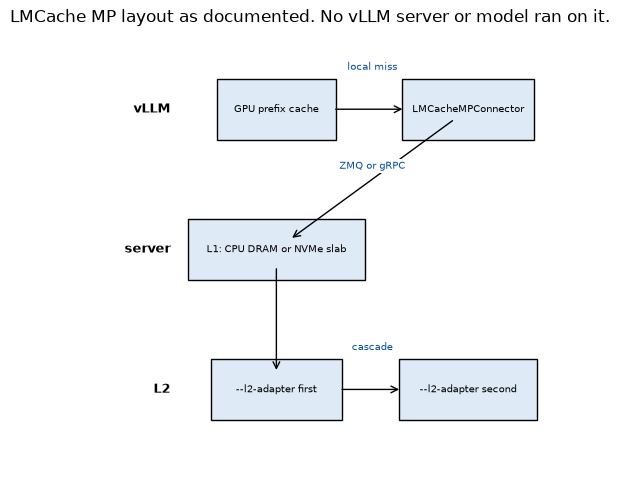

In [16]:
view.lane_diagram(
    {"vLLM": ["GPU prefix cache", "LMCacheMPConnector"],
     "server": ["L1: CPU DRAM or NVMe slab"],
     "L2": ["--l2-adapter first", "--l2-adapter second"]},
    [("GPU prefix cache", "LMCacheMPConnector", "local miss"),
     ("LMCacheMPConnector", "L1: CPU DRAM or NVMe slab", "ZMQ or gRPC"),
     ("L1: CPU DRAM or NVMe slab", "--l2-adapter first", ""),
     ("--l2-adapter first", "--l2-adapter second", "cascade")],
    title="LMCache MP layout as documented. No vLLM server or model ran on it.")

그림은 문서가 적은 구조를 옮긴 것입니다. 저자는 이 중 서버와 L1만 CPU에서 가짜 텐서로 돌렸고(7절), L2와 vLLM 연결은 돌리지 않았습니다. 조회 순서는 로컬 먼저, 외부 다음입니다(P8-30). LMCache는 hit에서 로컬 부분을 뺀 만큼만 불러오고, prompt 전체가 hit이면 마지막 token 하나는 다시 계산합니다(P8-31).

**chunk.** 저장 단위이고 기본 256 token이며 온전한 chunk만 저장합니다. 서버의 chunk 크기가 어느 cache group의 block token 수로 나누어떨어지지 않으면 시작 때 `ValueError`입니다(`LMCacheMPConnector`([lmcache_mp_connector.py:815](https://github.com/LMCache/LMCache/blob/3e11e10812b448142c6cdb177a3058652bd826fa/lmcache/integration/vllm/lmcache_mp_connector.py#L815)), P8-09). 실제 호출에서 chunk 256이 scheduler block의 배수가 아닌 GLM-5.3-Flash 구성은 그 줄에 닿기 전에 `vllm_block_size` 검사([vllm_multi_process_adapter.py:780](https://github.com/LMCache/LMCache/blob/3e11e10812b448142c6cdb177a3058652bd826fa/lmcache/integration/vllm/vllm_multi_process_adapter.py#L780))에서 다른 문구의 `ValueError`로 먼저 멈췄습니다. scheduler block은 group 폭의 최소공배수이고, 서로소에 가까운 폭이면 chunk가 너무 커져 쓸모없다고 경고합니다(`math.lcm`([lmcache_mp_connector.py:291](https://github.com/LMCache/LMCache/blob/3e11e10812b448142c6cdb177a3058652bd826fa/lmcache/integration/vllm/lmcache_mp_connector.py#L291)), P8-21). 그래서 chunk 크기는 모델과 TP에 묶입니다.

아래 셀은 나눗셈 조건만 옮긴 수업용 함수입니다. 폭은 문서와 코드 주석에 적힌 값이고, 실제 값은 connector가 시작 로그의 `group_tokens_per_block`으로 찍습니다. GLM-5.3-Flash 행의 폭은 문서가 아니라 `실제 클래스 호출` 값입니다. BF16, TP1, BLHNC에서 `[4352, 4352, 4352, 4352, 4352, 0]`이고 0은 저장하지 않는 tail group입니다. 같은 호출에서 TP4의 N은 1152였습니다. 다만 `FLASHINFER_MLA`를 import하지 못해 `FLASH_ATTN`을 대역으로 넣은 값이라 GPU의 N이 아닙니다(`docs/reference/lmcache.md`). GPU의 N은 시작 로그에서 읽습니다(P8-20).

In [17]:
def chunk_row(model, chunk, group_tokens):
    """LMCache connector의 '% tokens_per_block' 조건만 옮겼다. 그 밖의 시작 검사는 없다."""
    bad = [w for w in group_tokens if w and chunk % w]
    return {"model": model, "chunk": chunk, "group_tokens": str(group_tokens), "passes_this_check": not bad, "not_divisible_by": str(bad)}


view.table([chunk_row("DeepSeek-V4 comment", 256, [256, 64, 8, 4]),
            chunk_row("DeepSeek-V4 comment", 128, [256, 64, 8, 4]),
            chunk_row("DeepSeek-V4.1 recipe", 256, [64, 32]),
            chunk_row("DeepSeek-V4.1 recipe", 100, [64, 32]),
            chunk_row("GLM-5.3 (not -Flash) recipe", 1024, [64]),
            chunk_row("GLM-5.3-Flash class call", 256, [4352, 4352, 4352, 4352, 4352, 0]),
            chunk_row("GLM-5.3-Flash class call", 4352, [4352, 4352, 4352, 4352, 4352, 0])])

,model,chunk,group_tokens,passes_this_check,not_divisible_by
0,DeepSeek-V4 comment,256,"[256, 64, 8, 4]",True,[]
1,DeepSeek-V4 comment,128,"[256, 64, 8, 4]",False,[256]
2,DeepSeek-V4.1 recipe,256,"[64, 32]",True,[]
3,DeepSeek-V4.1 recipe,100,"[64, 32]",False,"[64, 32]"
4,GLM-5.3 (not -Flash) recipe,1024,[64],True,[]
5,GLM-5.3-Flash class call,256,"[4352, 4352, 4352, 4352, 4352, 0]",False,"[4352, 4352, 4352, 4352, 4352]"
6,GLM-5.3-Flash class call,4352,"[4352, 4352, 4352, 4352, 4352, 0]",True,[]


**관찰할 것.** `passes_this_check`가 `False`인 행의 `not_divisible_by`를 읽으세요. `True`는 이 나눗셈 하나만 통과했다는 뜻입니다. 조합이 동작한다는 뜻이 아닙니다. `GLM-5.3` 행은 단일 group `[64]`로 적힌 그 레시피 값이고(P8-09, P8-27), GLM-5.3-Flash가 아닙니다.

**축출.** `--eviction-policy`는 `LRU`, `ARC`, `IsolatedLRU`, `noop` 넷이고 파서 기본값이 없어 직접 줍니다. `IsolatedLRU`는 `cache_salt`마다 LRU를 두고, quota를 등록하지 않은 salt의 한도는 0 byte입니다. `noop`은 L1을 쓰기 버퍼로만 씁니다(`--eviction-policy`([config.py:905](https://github.com/LMCache/LMCache/blob/3e11e10812b448142c6cdb177a3058652bd826fa/lmcache/v1/distributed/config.py#L905)), P8-10).

**저장 범위.** 외부 connector는 기본으로 prompt 안의 온전한 chunk만 저장하고, 생성 token까지 저장하려면 `lmcache.mp.save_decode_cache`를 켭니다. `lmcache.mp.lazy_offload`는 기본 꺼짐이고 prefix caching이 꺼져 있으면 시작 때 거부합니다(P8-12). 에이전트 부하는 다음 턴이 앞 답변을 다시 보내니 이 기본값이 hit을 줄일 수 있습니다. 이 마지막 문장은 수업의 해석이고 잰 값이 없습니다.

**이 모델들에 쓸 수 없거나 검증이 없는 것.** CacheBlend는 레시피 표기가 DeepSeek-V4.1-Flash와 Kimi K3는 미지원, GLM-5.1/5.2와 GLM-5.3은 미검증입니다. 압축(CacheGen)은 MP 모드에 아직 구현되어 있지 않다고 문서가 적습니다(P8-11).

### LMCache 논문의 수치

아래는 모두 **자기 보고**입니다. 저자들이 자기 시스템을 잰 값이고 제3자 재현을 보지 못했습니다. 비교 대상은 v0.32.0이 아닙니다. 조건을 떼어 "최대 몇 배"로 옮기지 마세요.

| 주장 | 조건 | 근거 |
|---|---|---|
| 초록의 "최대 15배 처리량". 본문 범위는 같은 TTFT에서 최강 기준선 대비 2.3~14배, QPS=1의 TTFT 1.9~8.1배 작음 | 8×H100, 모델 다섯 종, 질문당 약 10K token 다중 라운드 Q&A, 40명으로 시작해 QPS로 사용자 추가 | P8-53 |
| 높은 QPS에서 TTFT 최소 3.7~6.8배, ITL 19~58% 감소 | 회사 F, G의 입출력 분포, 며칠 길이를 1시간 안으로 늘림, 원본이 아닌 모델 다섯 종 | P8-54 |
| 원격 저장 1.3~3배 처리량, PD의 평균 TTFT 1.53~1.84배, ITL 1.12~1.66배 낮음 | 15 Gbps 원격 서버와 TriviaQA 기반 부하, PD는 입력 8K와 출력 200 token의 임의 부하, 비교 대상은 그때의 vLLM 내장 PD | P8-55 |
| 19% 이상의 사용자가 저장한 token을 1.5회 넘게 재사용, 회사 C의 원격 로드가 전체 prefill 대비 TTFT 22~32% 낮음, 회사 G의 50% hit | 자발적 사용 추적기와 회사 이름을 밝히지 않은 운영 사례 | P8-56 |

### 명령 예: 저자는 실행하지 않았습니다

아래는 LMCache v0.5.6 트리의 GLM-5.2 레시피에 적힌 그대로입니다. 레시피가 적은 검증 조합은 **vLLM 0.23.0 + LMCache 0.4.7**, `zai-org/GLM-5.2-FP8`, 8 GPU입니다([glm5_2.rst:28](https://github.com/LMCache/LMCache/blob/3e11e10812b448142c6cdb177a3058652bd826fa/docs/source/recipes/glm5_2.rst#L28)). v0.32.0과 v0.5.6의 조합이 아니고, 그 조합을 검증했다는 문서는 찾지 못했습니다. 같은 레시피가 CacheBlend, CacheGen, MTP는 검증하지 않았다고 적습니다.

```bash
lmcache server \
    --port 6555 \
    --max-workers 8 \
    --l1-size-gb 100 \
    --eviction-policy LRU \
    --chunk-size 1024

vllm serve zai-org/GLM-5.2-FP8 \
    --tensor-parallel-size 8 \
    --tool-call-parser glm47 \
    --enable-auto-tool-choice \
    --reasoning-parser glm45 \
    --no-enable-prefix-caching \
    --kv-transfer-config \
    '{"kv_connector":"LMCacheMPConnector","kv_role":"kv_both","kv_connector_extra_config":{"lmcache.mp.port":6555}}'
```

읽을 점이 셋입니다. `--port`와 `lmcache.mp.port`가 같아야 합니다. `--max-workers`는 TP 크기입니다. `--no-enable-prefix-caching`은 재사용을 전부 LMCache로 보내려는 이 레시피의 선택입니다. 같은 문서 묶음의 Kimi K3, DeepSeek-V4.1-Flash, GLM-5.3은 반대로 켜고, Mamba 모델은 끄면 거부됩니다(P8-29). 다른 모델로 복사하지 마세요.

DeepSeek-V4.1-Flash 레시피는 다음 명령을 적고 "Validated with LMCache"라고 쓰지만 버전을 적지 않았고, 범위는 8 GPU의 텍스트 생성입니다([deepseek_v41_flash.rst:29](https://github.com/LMCache/LMCache/blob/3e11e10812b448142c6cdb177a3058652bd826fa/docs/source/recipes/deepseek_v41_flash.rst#L29), [deepseek_v41_flash.rst:140](https://github.com/LMCache/LMCache/blob/3e11e10812b448142c6cdb177a3058652bd826fa/docs/source/recipes/deepseek_v41_flash.rst#L140)). 레시피의 "태그 릴리스에 없음" 경고는 v0.32.0 트리와 다릅니다(`DeepseekV41ForCausalLM`이 등록표에 있습니다, [registry.py:373](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/model_executor/models/registry.py#L373)). 역시 실행하지 않았습니다.

```bash
lmcache server \
    --chunk-size 256 \
    --separate-object-groups \
    --l1-size-gb 100 \
    --eviction-policy LRU

vllm serve deepseek-ai/DeepSeek-V4.1-Flash \
    --tensor-parallel-size 8 \
    --enable-expert-parallel \
    --kv-cache-dtype fp8_ds_mla \
    --enable-prefix-caching \
    --kv-transfer-config \
    '{"kv_connector":"LMCacheMPConnector", "kv_role":"kv_both"}'
```

GLM-5.3-Flash용 LMCache 명령은 싣지 않습니다. 검증한 문서가 없고, LMCache 문서가 `-Flash`를 검증 범위 밖이라 적으며, GPU의 N 값과 checkpoint block 처리를 확인하지 못했기 때문입니다(P8-20, P8-26, 미확인). 7절의 실제 호출은 이 조합의 관문과 스케줄러 쪽 생성자까지이고, 이 모델을 LMCache에서 돌린 것이 아닙니다.

**왜 이렇게 설계했나.** connector의 코드 주석은 chunk 경계가 모든 group의 chunk 경계에 맞아야 group별 block ID 슬라이스가 어긋나지 않는다고 적습니다([lmcache_mp_connector.py:809](https://github.com/LMCache/LMCache/blob/3e11e10812b448142c6cdb177a3058652bd826fa/lmcache/integration/vllm/lmcache_mp_connector.py#L809)).

## 6. 모델별 지원 표 읽기

아래 표의 칸 표지는 다섯 종류이고 한 칸에 둘이 붙기도 합니다. 먼저 뜻을 봅니다.

| 칸 | 뜻 | 주의 |
|---|---|---|
| `문서 검증` | 문서가 검증했다고 적었습니다. 문서가 적은 버전을 칸에 옮겼고, 없으면 `버전 미기재`입니다 | 이 저장소가 돌려 본 것이 아닙니다. 버전이 v0.32.0과 다르면 그대로 옮겨 말할 수 없습니다 |
| `코드 읽기` | 코드 경로는 있지만 돌려 보지 않았습니다 | 동작한다는 뜻이 아닙니다. `실제 클래스 호출`이 함께 붙은 칸은 그 관문이나 생성자만 불렀습니다 |
| `코드가 막음` | 코드가 거부하는 줄이 있어 이 조합은 켜지지 않습니다. 그 줄을 적었습니다 | 서버에서 본 것이 아닙니다. `실제 클래스 호출`이 함께 붙은 칸만 그 거부를 호출로 확인했습니다 |
| `실제 클래스 호출` | CPU에서 그 칸의 관문이나 생성자를 실제 vLLM, LMCache 클래스로 불렀습니다 | SCHEDULER 역할 객체를 만들었을 뿐 worker 경로, 실제 가중치, 서버, GPU는 쓰지 않았고 byte 치수는 config와 코드를 읽어 맞춘 값입니다. 칸의 조합이 모델에서 돌아간다는 뜻이 아닙니다 |
| `미확인` | 근거를 찾지 못했습니다 | 안 된다는 뜻도 된다는 뜻도 아닙니다 |

`실제 클래스 호출`이 붙은 칸의 그 부분을 빼면 모두 코드 읽기와 문서 읽기의 결과입니다. 어떤 칸도 모델을 LMCache에 올려 돌려 본 결과가 아니고, vLLM v0.32.0과 LMCache v0.5.6 조합을 검증했다는 문서는 찾지 못했습니다. LMCache 호환 문서는 목록에 없는 조합을 스모크 테스트 전까지 미검증으로 보라고 적습니다([compatibility.rst:49-53](https://github.com/LMCache/LMCache/blob/3e11e10812b448142c6cdb177a3058652bd826fa/docs/source/getting_started/compatibility.rst#L49)).

| 모델 | 내장 prefix cache | 내장 offloading | LMCacheConnectorV1 | LMCacheMPConnector | PD 분리 |
|---|---|---|---|---|---|
| GLM-5.2 (`GlmMoeDsaForCausalLM`) | `코드 읽기`: 기본 켜짐(`enable_prefix_caching`([cache.py:141](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/cache.py#L141))). vLLM 레시피의 AMD MXFP4 예시와 성능 측정 안내는 끈다. 검증 문구는 못 봄 | `코드 읽기`, `실제 클래스 호출`: `OffloadingConnector`는 SupportsHMA. 이 모델 검증 문구는 못 봄. 호출은 LBHNC에서 SCHEDULER 생성까지이고 offloading 대상 group은 [0] 하나다. 저장과 복원은 실행하지 않음 | `실제 클래스 호출`: HMA가 자동으로 꺼지고 group 1개로 외부 어댑터의 SCHEDULER 생성까지 실행함(v0.5.6). `use_native`를 참으로 주면 동봉 어댑터가 v0.5.6에 없는 `CudaIPCWrapper`를 import해 `ImportError`다(P8-04). worker와 데이터 경로는 실행하지 않음. 문서 없음 | `문서 검증`, `실제 클래스 호출`: vLLM 0.23.0 + LMCache 0.4.7, `zai-org/GLM-5.2-FP8`, 8 GPU ([glm5_2.rst:15](https://github.com/LMCache/LMCache/blob/3e11e10812b448142c6cdb177a3058652bd826fa/docs/source/recipes/glm5_2.rst#L15), [glm5_2.rst:28](https://github.com/LMCache/LMCache/blob/3e11e10812b448142c6cdb177a3058652bd826fa/docs/source/recipes/glm5_2.rst#L28)). CacheBlend, CacheGen, MTP는 미검증. 호출은 문서의 버전과 별개로 v0.32.0 + v0.5.6에서 LBHNC SCHEDULER 생성까지 실행함 | `미확인`: `NixlBaseConnector` 공용 경로는 있으나 이 모델로 추적하지 않음. vLLM 레시피에 PD 절 없음 |
| GLM-5.3-Flash (`Glm5NextForCausalLM`) | `코드 읽기`: 켜져 있으면 Mamba `align` 자동 전환(`is_hybrid`, [vllm.py:2660-2661](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/vllm.py#L2660), `MambaModelConfig`, [config.py:685-687](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/model_executor/models/config.py#L685)) | `문서 검증`, `실제 클래스 호출`: `TieringOffloadingSpec`, 8 GiB CPU tier, `blocks_per_chunk: 1`, 4×H200 TP4, vLLM commit `d1b4028d7e`, `--enforce-eager`, `--max-model-len 16384`, 텍스트 전용, GSM8K 31/32는 소표본(레시피 "KV cache offloading"). 이 commit은 v0.32.0의 조상이 아니다(`gh api compare`: 갈라짐, 이 commit 쪽 1개, v0.32.0 쪽 1507개). 레시피가 요구하는 #57145는 v0.32.0에 있다. 호출은 commit 표기와 별개로 v0.32.0에서 SCHEDULER 생성까지 실행했고, scratch tail group은 offloading 대상에서 빠진다 | `코드가 막음`, `실제 클래스 호출`: 기본값이면 HMA가 꺼지고 `_promote_local_kv_cache_specs`([kv_cache_utils.py:1756-1760](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_utils.py#L1756))에서 `ValueError`. `--no-disable-hybrid-kv-cache-manager`를 주면 `create_connector`([factory.py:56-60](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/distributed/kv_transfer/kv_connector/factory.py#L56))에서 `ValueError`. 두 거부 줄을 실제 호출로 확인함 | `실제 클래스 호출`: 외부 구현 v0.5.6의 SCHEDULER 생성까지 실행함. 거부 경우(chunk 비배수, `--no-enable-prefix-caching`, batched token 부족, 내장판)도 실행함. worker 경로는 실행하지 않음. LMCache 문서가 `-Flash`를 검증 범위 밖이라 적음([glm5_3.rst:111-116](https://github.com/LMCache/LMCache/blob/3e11e10812b448142c6cdb177a3058652bd826fa/docs/source/recipes/glm5_3.rst#L111)), checkpoint block 처리 미확인(P8-26). 내장 `LMCacheMPConnectorUpstream`이면 `코드가 막음`(P8-14, P8-15). `--no-enable-prefix-caching`이면 `코드가 막음`(`validate_kv_cache_groups`([kv_cache_group_edits.py:159-172](https://github.com/LMCache/LMCache/blob/3e11e10812b448142c6cdb177a3058652bd826fa/lmcache/integration/vllm/kv_cache_group_edits.py#L159))) | `코드 읽기`: 레시피는 NIXL TP4+TP4 설정을 주지만 검증했다는 문구가 없음. `NixlBaseConnector`는 SupportsHMA |
| DeepSeek-V4 (레시피는 `DeepSeek-V4-Flash`) | `코드 읽기`: `SlidingWindowMLASpec`과 MLA group([compressor.py:184](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/deepseek_v4/compressor.py#L184), [attention.py:865](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/deepseek_v4/attention.py#L865)) | `코드 읽기`: offloading config가 `SlidingWindowMLASpec`을 다룸([config.py:18](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/distributed/kv_transfer/kv_connector/v1/offloading/config.py#L18), [config.py:208](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/distributed/kv_transfer/kv_connector/v1/offloading/config.py#L208)). 검증 문구는 못 봄 | `코드가 막음`, `실제 클래스 호출`: HMA 자동 꺼짐 뒤 승격 경로(`promotions`([kv_cache_utils.py:1731-1735](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_utils.py#L1731)))에서 `SlidingWindowMLASpec`을 MLA로 바꾸다 `TypeError`다. `replace_as` 호출([kv_cache_utils.py:1746](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_utils.py#L1746))이 `replace_as`([kv_cache_interface.py:138](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/kv_cache_interface.py#L138))의 대상 클래스 생성자에서 멈춘다(P8-15). connector 없이 `--disable-hybrid-kv-cache-manager`만 줘도 같다. 명시적 HMA면 `create_connector`([factory.py:56-60](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/distributed/kv_transfer/kv_connector/factory.py#L56)). 문서 없음 | `문서 검증`: `deepseek-ai/DeepSeek-V4-Flash`, 버전 미기재, 8 GPU 명령, MTP는 TP4와 gsm8k 100표본([deepseek_v4_flash.rst:21](https://github.com/LMCache/LMCache/blob/3e11e10812b448142c6cdb177a3058652bd826fa/docs/source/recipes/deepseek_v4_flash.rst#L21), [deepseek_v4_flash.rst:106-119](https://github.com/LMCache/LMCache/blob/3e11e10812b448142c6cdb177a3058652bd826fa/docs/source/recipes/deepseek_v4_flash.rst#L106)). 레시피는 개발 브랜치가 깨졌다고 경고. CacheGen 미검증 | `코드 읽기`: 레시피에 H200 단일 노드 Mooncake와 NIXL 명령이 있으나(이미지 `v0.28.0`) 그 절에 검증 문구 없음 |
| DeepSeek-V4.1-Flash | `코드 읽기`: `swa_bounded_replay` 기본 켜짐(P8-32) | `문서 검증`: GLM-5.3-Flash와 같은 commit `d1b4028d7e`, 4×H200 TP4, `TieringOffloadingSpec`, `--gpu-memory-utilization 0.95`, 텍스트 전용, 0909 체크포인트(레시피 "KV cache offloading"). 1017 가중치는 재실행 안 함 | `코드가 막음`, `실제 클래스 호출`: 결과는 거부로 같고 먼저 나는 예외가 다르다. `SlidingWindowMLASpec` 승격이 `TypeError`로 먼저 멈춘다(`replace_as` 호출([kv_cache_utils.py:1746](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_utils.py#L1746)) → `replace_as`([kv_cache_interface.py:138](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/kv_cache_interface.py#L138))). 압축기의 `CircularBufferSpec`([compressor.py:159-167](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/deepseek_v41/compressor.py#L159))이 일으키는 `ValueError`(`_promote_local_kv_cache_specs`([kv_cache_utils.py:1760](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_utils.py#L1760)))는 `SlidingWindowMLASpec`을 뺀 조합에서만 확인함. 명시적 HMA면 `create_connector`([factory.py:56-60](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/distributed/kv_transfer/kv_connector/factory.py#L56)) | `문서 검증`: `deepseek-ai/DeepSeek-V4.1-Flash`, 8 GPU, 버전 미기재, 텍스트 전용([deepseek_v41_flash.rst:17](https://github.com/LMCache/LMCache/blob/3e11e10812b448142c6cdb177a3058652bd826fa/docs/source/recipes/deepseek_v41_flash.rst#L17), [deepseek_v41_flash.rst:29](https://github.com/LMCache/LMCache/blob/3e11e10812b448142c6cdb177a3058652bd826fa/docs/source/recipes/deepseek_v41_flash.rst#L29), [deepseek_v41_flash.rst:140-142](https://github.com/LMCache/LMCache/blob/3e11e10812b448142c6cdb177a3058652bd826fa/docs/source/recipes/deepseek_v41_flash.rst#L140)). 레시피의 "태그 릴리스에 없음" 경고는 v0.32.0 트리와 다름([registry.py:373-376](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/model_executor/models/registry.py#L373)). CacheBlend, CacheGen 미지원. MTP는 미검증([deepseek_v41_flash.rst:117](https://github.com/LMCache/LMCache/blob/3e11e10812b448142c6cdb177a3058652bd826fa/docs/source/recipes/deepseek_v41_flash.rst#L117)) | `문서 검증`: 레시피가 GB200 NVL4 1P1D TP4 NIXL을 검증 배치라 부름. 전제는 vLLM 0.31.0 이상(레시피 "Prefill/Decode disaggregation", "Prerequisites") |
| Kimi-K3 | `코드 읽기`: MLA와 KDA hybrid. 레시피 프리셋은 `--enable-prefix-caching --prefix-match-unit 128` | `코드 읽기`: Mamba group 경로만 확인. 레시피는 MI355X prefill에 `SimpleCPUOffloadConnector`를 `MultiConnector`로 묶음 | `코드가 막음`, `실제 클래스 호출`: `MambaSpec`([kda.py:829-835](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/kimi_k3/nvidia/kda.py#L829))이 승격되지 않아 `_promote_local_kv_cache_specs`([kv_cache_utils.py:1756-1760](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_utils.py#L1756))에서 `ValueError`. 명시적 HMA면 `create_connector`([factory.py:56-60](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/distributed/kv_transfer/kv_connector/factory.py#L56)). 두 줄을 실제 호출로 확인했으나 치수는 config 스냅샷이 없어 가정한 값이고, 결과는 spec 종류로 정해진다 | `문서 검증`: 이미지 `vllm/vllm-openai:kimi-k3` + LMCache nightly 2026-07-27 이상 또는 정식 0.5.3 이상, 8×B300과 8×MI355X([kimi_k3.rst:18-21](https://github.com/LMCache/LMCache/blob/3e11e10812b448142c6cdb177a3058652bd826fa/docs/source/recipes/kimi_k3.rst#L18), [kimi_k3.rst:32-47](https://github.com/LMCache/LMCache/blob/3e11e10812b448142c6cdb177a3058652bd826fa/docs/source/recipes/kimi_k3.rst#L32)). 결과가 비트 단위로 같다는 보장은 없음([kimi_k3.rst:214-217](https://github.com/LMCache/LMCache/blob/3e11e10812b448142c6cdb177a3058652bd826fa/docs/source/recipes/kimi_k3.rst#L214)). 레시피의 vLLM 명령은 `--load-format dummy`를 넘기고([kimi_k3.rst:95](https://github.com/LMCache/LMCache/blob/3e11e10812b448142c6cdb177a3058652bd826fa/docs/source/recipes/kimi_k3.rst#L95)), 문서는 이를 무작위 가중치로 서빙 스택만 검증하는 설정이며 실제 가중치를 쓰려면 빼라고 적는다([kimi_k3.rst:145-147](https://github.com/LMCache/LMCache/blob/3e11e10812b448142c6cdb177a3058652bd826fa/docs/source/recipes/kimi_k3.rst#L145)). 따라서 이 칸의 검증은 실제 가중치로 한 것이 아니다. 이 저장소는 생성자도 실행하지 않음. ATOM PR은 별도 플러그인 경로라 이 칸의 근거가 아님 | `코드 읽기`: 레시피가 MI355X 1P1D, MoRIIO + prefill `SimpleCPUOffloadConnector`(`MultiConnector`) 명령을 주지만 이 배치를 검증했다는 문구는 없음. "real block verification"은 DSpark 초안 block을 실제로 검증한다는 뜻이고 레시피가 golden acceptance curve와 대비해 쓴 말이다. 명령은 InferenceX#4391의 1P1D c48 구성에 기반, 레시피 요구 vLLM 0.29.0 이상. 레시피의 NIXL 빌더 구성과 별개 |

칸을 읽는 법입니다. `코드가 막음`은 그 조합이 켜지지 않는다는 뜻이고, 이 표의 어떤 칸도 조합이 동작한다고 보장하지 않습니다. `실제 클래스 호출`의 결과 자체는 7절에서 봅니다.

표 밖의 주의가 하나 있습니다. `GLM-5.3`(`zai-org/GLM-5.3`, [glm5_3.rst:15](https://github.com/LMCache/LMCache/blob/3e11e10812b448142c6cdb177a3058652bd826fa/docs/source/recipes/glm5_3.rst#L15), [glm5_3.rst:27](https://github.com/LMCache/LMCache/blob/3e11e10812b448142c6cdb177a3058652bd826fa/docs/source/recipes/glm5_3.rst#L27))은 위 표의 GLM-5.3-Flash와 다른 항목입니다. LMCache가 검증했다고 적은 대상은 이쪽이고 버전 표기는 없습니다.

In [18]:
SUPPORT = {
    "GLM-5.2": ("code reading", "code reading + class call", "class call", "doc verified + class call", "unconfirmed"),
    "GLM-5.3-Flash": ("code reading", "doc verified + class call", "code blocks + class call", "class call", "code reading"),
    "DeepSeek-V4": ("code reading", "code reading", "code blocks + class call", "doc verified", "code reading"),
    "DeepSeek-V4.1-Flash": ("code reading", "doc verified", "code blocks + class call", "doc verified", "doc verified"),
    "Kimi-K3": ("code reading", "code reading", "code blocks + class call", "doc verified", "code reading"),
}
PATHS = ("builtin prefix cache", "builtin offloading", "LMCacheConnectorV1", "LMCacheMPConnector", "PD")
support = pd.DataFrame(SUPPORT, index=PATHS).T
LABELS = ("doc verified", "code reading", "code blocks", "class call", "unconfirmed")
with pd.option_context("display.max_colwidth", None):
    display(support)
pd.DataFrame({path: {label: sum(label in cell.split(" + ") for cell in support[path]) for label in LABELS} for path in PATHS})

,builtin prefix cache,builtin offloading,LMCacheConnectorV1,LMCacheMPConnector,PD
GLM-5.2,code reading,code reading + class call,class call,doc verified + class call,unconfirmed
GLM-5.3-Flash,code reading,doc verified + class call,code blocks + class call,class call,code reading
DeepSeek-V4,code reading,code reading,code blocks + class call,doc verified,code reading
DeepSeek-V4.1-Flash,code reading,doc verified,code blocks + class call,doc verified,doc verified
Kimi-K3,code reading,code reading,code blocks + class call,doc verified,code reading


,builtin prefix cache,builtin offloading,LMCacheConnectorV1,LMCacheMPConnector,PD
doc verified,0,2,0,4,1
code reading,5,3,0,0,3
code blocks,0,0,4,0,0
class call,0,2,5,2,0
unconfirmed,0,0,0,0,1


**관찰할 것.** 위쪽 표는 위 markdown 표의 칸 표지만 뽑은 것입니다(영어 표기, `class call`이 `실제 클래스 호출`). 한 칸에 표지가 둘이면 `+`로 잇고, 아래쪽 표는 표지마다 따로 셉니다. 어느 경로에 `doc verified`가 가장 많고, 어느 경로에는 0입니까? `class call`이 가장 많은 경로는 어디입니까? `builtin prefix cache` 열이 모두 `code reading`인 것은 무엇을 뜻합니까?

### GLM-5.3-Flash와 DeepSeek-V4.1에서 검증되지 않은 것

**GLM-5.3-Flash.**

- `문서 검증`은 내장 offloading 한 칸뿐입니다. 그 조건은 4×H200 TP4, vLLM commit `d1b4028d7e`, 텍스트 전용, GSM8K 31/32라는 소표본이고, 이 commit은 v0.32.0의 조상이 아닙니다.
- LMCache로 이 모델을 검증한 문서가 없습니다. `LMCacheMPConnector`는 `실제 클래스 호출`이고 LMCache v0.5.6 외부 구현의 SCHEDULER 생성까지입니다. worker 경로와 KV 저장, 복원은 실행하지 않았습니다. FlashKDA checkpoint block을 LMCache가 어떻게 저장하고 복원하는지는 미확인입니다(P8-26).
- `LMCacheConnectorV1`은 코드가 막고, 두 거부 줄을 실제 호출로 확인했습니다.
- PD는 레시피에 NIXL 설정이 있지만 검증했다는 문구가 없습니다.

**DeepSeek-V4.1-Flash.**

- 내장 offloading의 `문서 검증`은 위와 같은 commit, 0909 체크포인트, 텍스트 전용이고 1017 가중치로는 다시 돌리지 않았습니다.
- `LMCacheMPConnector`의 `문서 검증`은 버전 미기재, 8 GPU, 텍스트 전용입니다. CacheBlend와 CacheGen은 미지원이라고 적고, MTP는 아직 검증하지 않았다고 적습니다.
- PD의 `문서 검증`은 GB200 NVL4 1P1D TP4 NIXL이고 전제는 vLLM 0.31.0 이상입니다.
- 이미지 KV의 저장은 검증되지 않았습니다.
- `LMCacheConnectorV1`은 코드가 막고, 실제 호출에서 먼저 난 예외는 `TypeError`였습니다.

두 모델 모두 어떤 칸도 모델을 올려 돌려 본 결과가 아닙니다.

### 문서와 코드가 다를 때

코드가 맞습니다. 다만 대부분은 읽기만 했고, 실제로 부른 것은 `실제 클래스 호출`이 붙은 범위뿐입니다.

| 문서가 말하는 것 | 코드가 말하는 것 | 근거 |
|---|---|---|
| 예제 스크립트는 LMCache 경로에 `--kv-offloading-size 5`를 주고, `kv_offloading_size` 필드 설명은 용량처럼 읽힙니다 | 크기를 connector로 넘기지 않습니다. 용량은 `--l1-size-gb`가 정합니다 | P8-03, [vllm.py:1125-1127](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/vllm.py#L1125) |
| LMCache quickstart의 프로세스 내장 탭이 `--kv-offloading-backend lmcache`를 적습니다 | v0.32.0에서 그 경로는 MP connector로 풀립니다 | P8-04, [vllm.py:1130](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/vllm.py#L1130) |
| LMCache 호환 문서는 vLLM 0.20.0 이상도 이름의 기본값이 내장판이라 적습니다 | v0.32.0은 외부 구현을 먼저 고릅니다 | P8-05 |
| vLLM 예제 스크립트는 MP connector에 non-hybrid manager가 필요하다고 적고 `--disable-hybrid-kv-cache-manager`를 줍니다 | 내장판의 사정입니다. LMCache v0.5.6은 HMA를 지원하고, 이 스크립트를 hybrid 모델에 그대로 쓰면 7절의 오류로 멈출 수 있습니다 | P8-17, [cpu_offload_lmcache_mp.sh:31](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/examples/disaggregated/lmcache/cpu_offload_lmcache_mp.sh#L31) |
| LMCache는 `all` 모드도 받는다고 적습니다 | v0.32.0의 `MambaCacheMode`에는 `align`과 `none`만 있습니다 | P8-19, [cache.py:63](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/cache.py#L63) |
| LMCache 레시피는 scratch spec을 `KpoolTailSpec`이라 부릅니다 | v0.32.0에 그 이름이 없고 tail cache는 `CircularBufferSpec`입니다 | P8-27, [attention.py:170](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/glm5next/common/attention.py#L170) |
| Kimi K3 레시피는 read lock 만료가 `invalid_block_ids`로 보고되어 치명적이라 적습니다 | LMCache v0.5.6은 group이 둘 이상이면 요청 단위 `failed_recving`으로 보고합니다 | P8-34, P8-52, [lmcache_mp_connector.py:1130](https://github.com/LMCache/LMCache/blob/3e11e10812b448142c6cdb177a3058652bd826fa/lmcache/integration/vllm/lmcache_mp_connector.py#L1130) |
| 분리 prefill 문서는 connector를 9종이라 적고 8개만 나열합니다 | 등록표에는 그보다 많습니다 | P8-41 |
| GLM-5.3-Flash 레시피는 Hopper가 이 모델의 FP8 KV를 지원하지 않는다고 적습니다 | `FLASHINFER_MLA_SPARSE_SM90`의 지원 목록에 `fp8`이 있고 막는 줄을 찾지 못했습니다. CPU 호출에서 spec까지는 나왔지만 SM 값과 FlashInfer 유무를 지정한 것이고 서버 실행이 아니므로, 2절의 권장은 레시피를 따릅니다 | P8-50, [flashinfer_mla_sparse_sm90.py:148-153](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/attention/backends/mla/flashinfer_mla_sparse_sm90.py#L148) |
| 최적화 문서와 시작 안내 문구는 `--kv-cache-memory`로 적습니다 | 등록된 플래그는 `--kv-cache-memory-bytes`입니다 | P8-49, [arg_utils.py:1363](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/engine/arg_utils.py#L1363) |

## 7. hybrid 제약과 KDA 상태 복원

표의 `코드가 막음`이 어디서 오는지 봅니다. 공식 문서에는 이 분기 설명이 없습니다. 코드에서 읽었고, 아래에서 실제 클래스 호출 결과로 대조합니다(P8-14, P8-15).

connector가 HMA를 지원하는지는 `SupportsHMA` 상속 하나로 판정합니다(`SupportsHMA`([base.py:100](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/distributed/kv_transfer/kv_connector/v1/base.py#L100)), P8-13). 입력 플래그는 `--disable-hybrid-kv-cache-manager` 하나이고 경우가 셋입니다.

| 플래그 | connector가 지원 | connector가 미지원 |
|---|---|---|
| 지정 안 함(기본) | HMA 켜짐 | 경고만 찍고 끔(`need_disable_hybrid_kv_cache_manager`([vllm.py:2177-2178](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/vllm.py#L2177))) |
| `--no-disable-...`(명시적 켬) | HMA 켜짐 | `create_connector`([factory.py:56-60](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/distributed/kv_transfer/kv_connector/factory.py#L56))에서 `ValueError` |
| `--disable-...`(명시적 끔) | HMA 꺼짐 | HMA 꺼짐 |

이 표는 connector 축만 봅니다. 기본값일 때는 비 GPU 플랫폼과 chunked local attention도 HMA를 끄는 조건입니다(`need_disable_hybrid_kv_cache_manager`([vllm.py:2145-2168](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/vllm.py#L2145))).

HMA가 꺼지면 `unify_hybrid_kv_cache_specs`가 모든 층을 한 종류로 맞추려 합니다(`unify_hybrid_kv_cache_specs`([kv_cache_utils.py:2174](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_utils.py#L2174))). 승격표에는 `SlidingWindowMLASpec`, `SlidingWindowSpec`, `ChunkedLocalAttentionSpec`만 있습니다(`promotions`([kv_cache_utils.py:1731-1735](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_utils.py#L1731))). `MambaSpec`과 `CircularBufferSpec`은 여기 없어서, 다른 attention과 섞이면 시작이 멈춥니다(P8-15). 표에 있다고 무사한 것도 아닙니다. `SlidingWindowMLASpec`을 MLA와 섞어 승격하면 `replace_as` 호출([kv_cache_utils.py:1746](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_utils.py#L1746))이 넘긴 `bounded_replay` 필드([kv_cache_interface.py:956](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/kv_cache_interface.py#L956))를 대상 클래스가 받지 못합니다. 이 필드는 값이 참이든 거짓이든 같습니다. 내장 `LMCacheMPConnectorUpstream`과 `LMCacheConnectorV1`은 단일 group만 전제합니다(P8-16).

### 실제 클래스 호출로 본 관문과 저장

저자가 CPU에서 실제 vLLM과 LMCache 클래스를 불러 저장한 결과를 읽습니다(`data/reference_lmcache.json`, `docs/reference/lmcache.md`). 층 객체는 가중치 없이 만들었고 byte 치수는 config와 코드를 읽어 맞췄으므로, 아래의 GLM-5.3-Flash와 DeepSeek-V4.1-Flash는 그 모델 모양의 spec입니다. 아래 셀은 저장된 행을 읽을 뿐 아무것도 실행하지 않습니다. 표에 넣으려고 오류 문구의 backtick은 뺐습니다. 맨 아래 표는 관문을 지난 뒤 SCHEDULER 역할 생성자까지 간 결과입니다.

In [19]:
# 실패 재현: HMA 관문과 생성자에서 멈추는 조합. 저자가 CPU에서 실제 클래스를 부른 저장 결과를 읽는다
LMCACHE = json.loads((DATA_DIR / "reference_lmcache.json").read_text(encoding="utf-8"))
GATING = LMCACHE["parts"]["gating"]["rows"]
SPEC_MODELS = ("GLM-5.3-Flash", "DeepSeek-V4.1-Flash")
FLAG_COLUMNS = {"default": "default", "--disable-hybrid-kv-cache-manager": "disable",
                "--no-disable-hybrid-kv-cache-manager": "no_disable"}
GATE_PATHS = (("LMCacheConnectorV1", "lmrun_external", "LMCacheConnectorV1"),
              ("LMCacheMPConnector (external v0.5.6)", "lmrun_external", "LMCacheMPConnector"),
              ("LMCacheMPConnectorUpstream (bundled)", "lmrun_upstream", "LMCacheMPConnector"),
              ("OffloadingConnector", "lmrun_external", "OffloadingConnector"))
CONSTRUCT_CASES = ("GLM-5.3-Flash + chunk 256 (default)",
                   "GLM-5.3-Flash + --no-enable-prefix-caching (Mamba none)",
                   "GLM-5.3-Flash + max_num_batched_tokens < N",
                   "GLM-5.3-Flash BLHNC + chunk = scheduler block + --separate-object-groups",
                   "GLM-5.3-Flash BLHNC + chunk = scheduler block, no --separate-object-groups",
                   "GLM-5.3-Flash LBHNC + chunk = scheduler block + --separate-object-groups",
                   "DeepSeek-V4.1-Flash BLHNC + chunk = scheduler block + --separate-object-groups",
                   "DeepSeek-V4.1-Flash LBHNC geometry probe",
                   "no server listening")


def error_place(error):
    return f"{error['type']} at {error['raised_at'].rsplit('/', 1)[-1]}"


def gate_text(row):
    if row["outcome"] == "gate_passed":
        return "gate passed, HMA " + ("off" if row["hma_disabled"] else "on")
    return error_place(row["exception"])


def gate_row(model, label, env, connector):
    found = {r["flag"]: gate_text(r) for r in GATING[env] if (r["model"], r["connector"]) == (model, connector)}
    return {"model": model, "connector": label, **{name: found[flag] for flag, name in FLAG_COLUMNS.items()}}


def construct_row(row):
    if row["outcome"] == "constructed":
        detail = f"group_tokens_per_block {row['group_tokens_per_block']}, scheduler block {row['scheduler_block_size']}"
    else:
        sentence = row["exception"]["message"].split(". ")[0]
        shown = sentence if len(sentence) <= 130 else sentence[:130] + " ..."
        detail = f"{row['exception']['type']} at {row['raised_at'].rsplit('/', 1)[-1]}: {shown}"
    return {"case": row["case"], "outcome": row["outcome"], "detail": detail}


refused = [r for env in ("lmrun_external", "lmrun_upstream") for r in GATING[env]
           if r["model"] in SPEC_MODELS and r["outcome"] == "refused"]
messages = {(r["exception"]["type"], r["exception"]["raised_at"].rsplit("/", 1)[-1], r["exception"]["message"].replace("`", ""))
            for r in refused}
by_case = {r["case"]: r for r in LMCACHE["parts"]["connector_construct"]["rows"]}
print("status:", LMCACHE["status"], "/ vLLM", LMCACHE["versions"]["vllm"], "/ LMCache", LMCACHE["versions"]["lmcache"])
with pd.option_context("display.max_colwidth", None):
    display(view.table([gate_row(m, *path) for m in SPEC_MODELS for path in GATE_PATHS]
                       + [{"model": r["model"], "connector": "no connector", "default": "-",
                           "disable": gate_text(r) if r["outcome"] == "refused" else r["outcome"], "no_disable": "-"}
                          for r in LMCACHE["parts"]["gating"]["no_connector"] if r["model"] in SPEC_MODELS]))
    display(pd.DataFrame(sorted(messages), columns=["type", "raised_at", "message"]))
    display(view.table([construct_row(by_case[name]) for name in CONSTRUCT_CASES]))
no_lmcache = GATING["refrun_LMCacheMPConnector"][0]
print("lmcache가 없는 환경의 LMCacheMPConnector:", error_place(no_lmcache["exception"]))

status: partial / vLLM v0.32.0 / LMCache v0.5.6


,model,connector,default,disable,no_disable
0,GLM-5.3-Flash,LMCacheConnectorV1,ValueError at kv_cache_utils.py:1760,ValueError at kv_cache_utils.py:1760,ValueError at factory.py:57
1,GLM-5.3-Flash,LMCacheMPConnector (external v0.5.6),"gate passed, HMA on",ValueError at kv_cache_utils.py:1760,"gate passed, HMA on"
2,GLM-5.3-Flash,LMCacheMPConnectorUpstream (bundled),ValueError at kv_cache_utils.py:1760,ValueError at kv_cache_utils.py:1760,ValueError at factory.py:57
3,GLM-5.3-Flash,OffloadingConnector,"gate passed, HMA on",ValueError at kv_cache_utils.py:1760,"gate passed, HMA on"
4,DeepSeek-V4.1-Flash,LMCacheConnectorV1,TypeError at kv_cache_interface.py:138,TypeError at kv_cache_interface.py:138,ValueError at factory.py:57
5,DeepSeek-V4.1-Flash,LMCacheMPConnector (external v0.5.6),"gate passed, HMA on",TypeError at kv_cache_interface.py:138,"gate passed, HMA on"
6,DeepSeek-V4.1-Flash,LMCacheMPConnectorUpstream (bundled),TypeError at kv_cache_interface.py:138,TypeError at kv_cache_interface.py:138,ValueError at factory.py:57
7,DeepSeek-V4.1-Flash,OffloadingConnector,"gate passed, HMA on",TypeError at kv_cache_interface.py:138,"gate passed, HMA on"
8,GLM-5.3-Flash,no connector,-,ValueError at kv_cache_utils.py:1760,-
9,DeepSeek-V4.1-Flash,no connector,-,TypeError at kv_cache_interface.py:138,-


,type,raised_at,message
0,TypeError,kv_cache_interface.py:138,MLAAttentionSpec.__init__() got an unexpected keyword argument 'bounded_replay'
1,ValueError,factory.py:57,Connector LMCacheConnectorV1 does not support HMA but HMA is enabled. Please set --disable-hybrid-kv-cache-manager.
2,ValueError,factory.py:57,Connector LMCacheMPConnectorUpstream does not support HMA but HMA is enabled. Please set --disable-hybrid-kv-cache-manager.
3,ValueError,kv_cache_utils.py:1760,Failed to promote local KV cache specs to one unified type.


,case,outcome,detail
0,GLM-5.3-Flash + chunk 256 (default),refused,ValueError at vllm_multi_process_adapter.py:780: LMCache chunk size 256 must be a multiple of 4352 (the vLLM block size scaled by decode_context_parallel_size)
1,GLM-5.3-Flash + --no-enable-prefix-caching (Mamba none),refused,ValueError at kv_cache_group_edits.py:168: LMCache cannot serve this model's KV cache groups: group 0: MambaSpec with mamba_cache_mode='none' (only 'align' and 'all' keep re ...
2,GLM-5.3-Flash + max_num_batched_tokens < N,refused,ValueError at lmcache_mp_connector.py:421: Mamba-hybrid models with LMCache require max_num_batched_tokens >= block_size so every prefill step advances at least one full blo ...
3,GLM-5.3-Flash BLHNC + chunk = scheduler block + --separate-object-groups,constructed,"group_tokens_per_block [4352, 4352, 4352, 4352, 4352, 0], scheduler block 4352"
4,"GLM-5.3-Flash BLHNC + chunk = scheduler block, no --separate-object-groups",constructed,"group_tokens_per_block [4352, 4352, 4352, 4352, 4352, 0], scheduler block 4352"
5,GLM-5.3-Flash LBHNC + chunk = scheduler block + --separate-object-groups,constructed,"group_tokens_per_block [4352, 4352, 4352, 4352, 4352, 69632, 0], scheduler block 69632"
6,DeepSeek-V4.1-Flash BLHNC + chunk = scheduler block + --separate-object-groups,constructed,"group_tokens_per_block [0, 0, 0, 0, 0, 0, 0, 64, 0], scheduler block 64"
7,DeepSeek-V4.1-Flash LBHNC geometry probe,refused,NotImplementedError at kv_cache_utils.py:1347: Layer model.layers.2.self_attn.indexer.k_cache: page size is not divisible by the maximum page size and cannot be padded
8,no server listening,refused,ConnectionError at vllm_multi_process_adapter.py:332: Cannot reach the LMCache MP server at 'tcp://localhost:59999' within 2.0s


lmcache가 없는 환경의 LMCacheMPConnector: ModuleNotFoundError at lmcache_mp_connector.py:11


**관찰할 것.** 맨 위 표에서 GLM-5.3-Flash와 DeepSeek-V4.1-Flash의 `LMCacheConnectorV1` 행을 비교하세요. 둘 다 거부되는데 예외 종류가 어떻게 다릅니까? 외부 `LMCacheMPConnector` 행에서 `disable` 칸만 거부되는 이유를 위 분기표로 설명하세요. 맨 아래 표에서 chunk 256 행과 chunk가 scheduler block과 같은 행을 비교하세요.

GLM-5.3-Flash의 `ValueError`는 `MambaSpec`과 `CircularBufferSpec`이 승격표에 없어서 납니다. V4.1의 `TypeError`는 승격표에 있는 `SlidingWindowMLASpec`을 바꾸다 `bounded_replay`에서 먼저 납니다. `CircularBufferSpec` 때문에 나는 `ValueError`는 `SlidingWindowMLASpec`을 뺀 조합에서만 확인했습니다. `no connector` 행에서 보듯 connector 없이 `--disable-hybrid-kv-cache-manager`만 줘도 결과가 같으므로 connector 문제가 아니라 HMA를 끈 경로의 문제입니다. 이 동작이 v0.32.0 이후에 고쳐졌는지는 확인하지 않았습니다(P8-15).

`gate passed`와 `constructed`는 그 단계를 지났다는 뜻입니다. KV를 저장하거나 복원한 것이 아닙니다. 폭 0은 저장하지 않는 group입니다. V4.1에서 저장 대상은 폭 64인 group 하나였습니다. `BLHNC`와 `LBHNC`는 KV cache layout 값이고, 표의 생성 행은 layout을 지정해 부른 것입니다. GLM-5.3-Flash는 `LBHNC`에서 scheduler block이 69632로 커집니다. GPU worker가 어느 layout을 고르는지는 미확인입니다. V4.1이 `LBHNC`에서 `NotImplementedError`로 끝난 것도 BF16 기본값 산술의 결과라 V4.1 offloading이 막힌다는 근거로 쓰면 안 됩니다(`docs/reference/lmcache.md`).

다음 셀은 저장 쪽입니다. 로컬 `lmcache server`와 실제 ZMQ 클라이언트로 가짜 CPU 텐서를 넣고 꺼낸 결과입니다. 1 chunk는 4096 byte인 부동소수 텐서이고 어떤 모델도 관여하지 않습니다.

In [20]:
STORAGE = LMCACHE["parts"]["storage"]["rows"]
trip, evict, split, zero = STORAGE["roundtrip"], STORAGE["eviction"], STORAGE["separate_object_groups"], STORAGE["chunk_size_zero"]
display(view.table([
    {"scenario": "chunk 16, before store", "hit_chunks": trip["hit_before_store"], "note": "nothing stored yet"},
    {"scenario": "chunk 16, after store", "hit_chunks": trip["hit_after_store"],
     "note": f"stored {trip['stored_chunks']} chunks, last {trip['trailing_partial_tokens_not_stored']} tokens not stored"},
    {"scenario": "other cache_salt", "hit_chunks": trip["hit_other_salt"], "note": "same tokens, different salt"},
    {"scenario": "only the start matches", "hit_chunks": trip["hit_diverging_prefix"], "note": "full overlapping chunks only"},
    {"scenario": "chunk 32, separate object groups", "hit_chunks": split["hit_after_store"],
     "note": "client registered one group, so nothing was split"},
    {"scenario": "chunk 0", "hit_chunks": "-", "note": f"server_ready {zero['server_ready']}, the value is not refused"}]))
display(view.table([{**r, "shape": str(r["shape"])} for r in trip["retrieved"]]))

kept = evict["presence_by_write_order"]
view.table([{"policy": "LRU", "chunk_bytes": evict["chunk_bytes"], "l1_total_bytes": evict["l1_after"]["memory_total_bytes"],
             "written_chunks": evict["committed_chunks"], "first_chunk_kept": bool(kept[0]), "last_chunk_kept": bool(kept[-1]),
             "kept_chunks_are_the_latest_run": all(kept[kept.index(1):])}])

,scenario,hit_chunks,note
0,"chunk 16, before store",0,nothing stored yet
1,"chunk 16, after store",3,"stored 3 chunks, last 5 tokens not stored"
2,other cache_salt,0,"same tokens, different salt"
3,only the start matches,1,full overlapping chunks only
4,"chunk 32, separate object groups",2,"client registered one group, so nothing was split"
5,chunk 0,-,"server_ready True, the value is not refused"


,start,success,shape,value
0,0,True,"[2, 2, 16, 16]",1.0
1,16,True,"[2, 2, 16, 16]",17.0
2,32,True,"[2, 2, 16, 16]",33.0


,policy,chunk_bytes,l1_total_bytes,written_chunks,first_chunk_kept,last_chunk_kept,kept_chunks_are_the_latest_run
0,LRU,4096,107374,60,False,True,True


**관찰할 것.** 첫 표에서 `hit_chunks`가 0인 두 행과 chunk 16으로 저장한 뒤의 행을 비교하세요. 가운데 표의 `value`는 넣을 때 채운 값(1.0 + `start`)이니 넣은 값이 그대로 돌아왔는지 확인하세요. 마지막 표의 `first_chunk_kept`와 `last_chunk_kept`는 무엇을 말합니까?

chunk로 저장한다는 5절의 말이 여기서 보입니다. 끝에 남은 5 token은 chunk를 채우지 못해 저장되지 않았고, 앞부분만 같은 token은 온전히 겹치는 chunk만 hit입니다. L1이 작으면 LRU가 오래된 chunk부터 내보내 맨 처음 chunk는 없고 가장 최근 쪽 연속 구간만 남습니다. 남는 chunk 수는 실행마다 달라서 적지 않습니다. `--separate-object-groups`의 실제 나누기와 `--chunk-size 0`의 동작은 여기서 알 수 없습니다. 서버가 그 값을 거부하지 않았다는 것만 봤습니다.

**이 결과가 증명하는 것은 connector 관문과 저장 경로의 동작뿐입니다.** 어떤 모델의 KV도 LMCache에 들어가거나 복원되지 않았고, 다른 salt의 hit이 0인 것도 서버 저장 경로의 사실입니다. worker 역할, 실제 가중치, GPU backend, L2는 돌리지 않았고, FlashKDA checkpoint block의 저장과 복원은 미확인입니다(P8-26). LMCache 설치도 PyPI wheel이 macOS에서 막혀 소스를 GPU 확장 없이 빌드한 것입니다.

**LMCache로 Mamba 계열을 쓸 때의 조건**은 넷입니다(P8-19). Mamba 캐시 모드 `align`, 서버의 `--chunk-size`가 통합 block 크기 N의 배수, 서버의 `--separate-object-groups`, `--max-num-batched-tokens`가 N 이상. 첫째, 둘째, 넷째는 connector가 시작 때 `ValueError`로 거부하고(`validate_kv_cache_groups`([kv_cache_group_edits.py:159](https://github.com/LMCache/LMCache/blob/3e11e10812b448142c6cdb177a3058652bd826fa/lmcache/integration/vllm/kv_cache_group_edits.py#L159)), 5절의 chunk 검사, `validate_mamba_step_alignment`([lmcache_mp_connector.py:371](https://github.com/LMCache/LMCache/blob/3e11e10812b448142c6cdb177a3058652bd826fa/lmcache/integration/vllm/lmcache_mp_connector.py#L371))), 셋째는 문서상 요구입니다([hybrid_models.rst:233-234](https://github.com/LMCache/LMCache/blob/3e11e10812b448142c6cdb177a3058652bd826fa/docs/source/mp/hybrid_models.rst#L233)). 실제 호출에서 셋째를 빼도 SCHEDULER 생성자는 통과했습니다. 생성자가 검사하지 않을 뿐이고 worker와 데이터 경로를 돌리지 않았으니 필요 없다는 뜻이 아닙니다. N은 시작 로그의 "Setting attention block size"에서 읽습니다([interface.py:1097](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/platforms/interface.py#L1097), P8-20). 위 표의 4352는 GPU backend를 대역으로 넣은 CPU 호출의 값입니다.

### 복원한 MLA prefix에 경계가 맞아야 하는 이유

MLA KV는 token마다 record가 있으니 앞에서 몇 개든 잘라 쓸 수 있습니다. KDA 상태는 다릅니다. "여기까지 읽은 뒤의 상태" 하나이고, 앞으로 되감을 수 없습니다. 어떤 token부터 이어서 계산하려면 바로 그 경계의 상태가 있어야 합니다. 그래서 복원 길이는 두 쪽이 모두 가진 가장 긴 경계로 내려갑니다. 4절의 `discarded_by_checkpoint_tokens`가 이것입니다. 아래 그림은 수업이 만든 예이고 간격 3은 수업이 정한 값입니다.

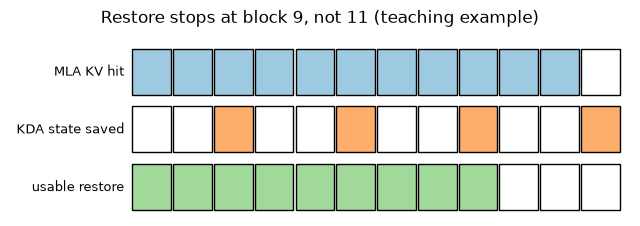

In [21]:
def boundary_figure(kv_blocks=11, total=12, every=3):
    usable = kv_blocks // every * every
    fig, ax = plt.subplots(figsize=(8, 2.4))
    for i in range(total):
        ax.add_patch(Rectangle((i, 2), 0.95, 0.8, facecolor="#9ecae1" if i < kv_blocks else "#ffffff", edgecolor="black"))
        boundary = (i + 1) % every == 0
        ax.add_patch(Rectangle((i, 1), 0.95, 0.8, facecolor="#fdae6b" if boundary else "#ffffff", edgecolor="black"))
        ax.add_patch(Rectangle((i, 0), 0.95, 0.8, facecolor="#a1d99b" if i < usable else "#ffffff", edgecolor="black"))
    for y, label in ((2, "MLA KV hit"), (1, "KDA state saved"), (0, "usable restore")):
        ax.text(-0.2, y + 0.4, label, ha="right", va="center", fontsize=9)
    ax.set_xlim(-3, total + 0.2)
    ax.set_ylim(-0.1, 3.1)
    ax.axis("off")
    ax.set_title(f"Restore stops at block {usable}, not {kv_blocks} (teaching example)")
    plt.close(fig)
    return fig


boundary_figure()

v0.32.0 코드의 근거는 다음과 같습니다. 공식 문서는 align이면 Mamba 상태가 block 격자에만 저장되어 hit이 block 경계에서만 재개된다고 한 문장으로 적습니다([automatic_prefix_caching.md:18](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/features/automatic_prefix_caching.md#L18)). 예외로, 기본 꺼짐인 `--enable-mamba-shared-prefix-checkpoint`는 shared-prefix 접합점에도 checkpoint를 남깁니다(같은 절, 조건 넷). 아래 세부는 코드에서 읽었습니다(P8-23).

- `mamba_cache_mode`의 `align`은 스텝 마지막 token이 block 경계일 때만 상태를 남깁니다(`mamba_cache_mode`([cache.py:189-195](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/cache.py#L189))).
- block table의 칸 p는 정확히 (p+1)×block_size token 뒤의 상태입니다([scheduler.py:502-503의 주석](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L502)).
- 로컬 hit이 group끼리 어긋났는데 외부 token이 받쳐 주지 않으면 scheduler가 모든 group이 동의하는 경계로 되돌립니다(`get_computed_blocks`([scheduler.py:1029-1037](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L1029))). `supports_divergent_local_hybrid_hits`를 쓰지 않는 LMCache v0.5.6 경로의 로컬 hit도 그 경계까지입니다(P8-28).

GLM-5.3-Flash에서는 `Glm5NextLinearAttention`의 spec이 `MambaSpec`이고, FlashKDA면 checkpoint block 1개와 정렬 16이 붙습니다(`Glm5NextLinearAttention.get_kv_cache_spec`([kda.py:168-176](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/glm5next/common/kda.py#L168))). 내장 offloading은 hit 창을 Mamba block 크기로 내리고 불러올 key를 token 범위와 묶습니다. 이 동작은 코드 읽기이고 경계 정합성을 실행으로 확인한 것은 아닙니다(P8-24).

LMCache v0.5.6은 합의를 다르게 합니다(P8-25). 저장 가능한 길이는 가장 덜 채운 group이 정합니다([lmcache_mp_metadata.py:281](https://github.com/LMCache/LMCache/blob/3e11e10812b448142c6cdb177a3058652bd826fa/lmcache/integration/vllm/lmcache_mp_metadata.py#L281)). 조회는 (object group, kv rank)마다 한 줄씩 제출해([lookup.py:255](https://github.com/LMCache/LMCache/blob/3e11e10812b448142c6cdb177a3058652bd826fa/lmcache/v1/multiprocess/modules/lookup.py#L255)) `fold_unfold_grouped`로 모델 전체 hit 길이 하나로 접습니다(`fold_unfold_grouped`([fold.py:309](https://github.com/LMCache/LMCache/blob/3e11e10812b448142c6cdb177a3058652bd826fa/lmcache/v1/distributed/bitmap_ops/fold.py#L309))). 설계 문서는 MTP에서 prompt 마지막 block의 경계 상태가 기록되지 않는 경우를 적습니다. 그 chunk는 서버가 건너뛰고 다음 hit이 한 chunk 앞에서 끝나며, 이 동작에는 `--separate-object-groups`와 Mamba block 크기와 같은 chunk 크기가 필요합니다([hybrid-kv-cache-groups.md:212-227](https://github.com/LMCache/LMCache/blob/3e11e10812b448142c6cdb177a3058652bd826fa/docs/design/integration/vllm/hybrid-kv-cache-groups.md#L212)). 2절의 MTP가 hit 길이에도 닿는다는 뜻입니다.

**미확인이거나 옮기면 안 되는 것.**

- `lmcache/integration/vllm`에는 `prefill_checkpoint` 참조가 없습니다. FlashKDA checkpoint block의 저장과 복원은 미확인입니다(P8-26).
- `ROCm/ATOM` 저장소의 PR #2268은 복원한 MLA prefix에 같은 경계의 KDA 상태가 없으면 결과가 조용히 틀린다고 적습니다. 이것은 vLLM 0.28의 플러그인 경로에 대한 자기 보고이고, v0.32.0의 `LMCacheMPConnector`에 그대로 옮겨 말할 수 없습니다(P8-22).
- K3 보고서의 물리 block과 hash block 분리는 그 시스템의 설명입니다(P7-53, 제작사 주장).
- scratch group은 저장하지 않습니다. `CircularBufferSpec`은 복원되지 않고 다시 계산합니다(P8-18).

**왜 이렇게 설계했나.** scheduler 주석은 더 깊은 로컬 hit을 외부 token이 받쳐 주지 않으면 그 재개 경계에 유효한 Mamba 상태가 없기 때문이라고 적습니다([scheduler.py:1030-1032의 주석](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L1030)).

## 8. load 실패 정책

miss와 load 실패는 다릅니다. miss는 외부에 없다는 답이고, 그 token을 prefill로 계산하면 끝입니다. load 실패는 hit이라고 답한 뒤 가져오다 실패한 것입니다.

| 일 | 무슨 일이 일어나는가 | 근거 |
|---|---|---|
| 외부에 없음(miss) | 외부 hit이 0이고 계산합니다. 오류가 아닙니다 | P8-30 |
| 조회 답이 아직 없음 | connector가 `None`을 돌려주면 이번 step은 건너뛰고 다음에 다시 묻습니다 | P8-30 |
| load 실패, `kv_load_failure_policy: fail` | 요청이 `FINISHED_ERROR`로 끝납니다. 다시 계산하지 않습니다 | P8-33 |
| load 실패, `kv_load_failure_policy: recompute` | 재스케줄합니다. 요청 단위 보고(`failed_recving`)면 계산한 token 수를 0으로 되돌리고, 단일 group의 block 단위 보고면 처음 실패한 block 앞까지 남깁니다(`_update_requests_with_invalid_blocks`([scheduler.py:3314-3315](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L3314)), `_handle_failed_recving`([scheduler.py:3341-3354](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L3341))) | P8-33 |
| 다중 group 모델에서 block 단위 실패 보고 | `RuntimeError`입니다. block ID가 group 안에서만 유일해 요청으로 되돌릴 수 없습니다 | P8-34 |
| LMCache v0.5.6, group 둘 이상 | 요청 단위 `failed_recving`으로 보고합니다. 그 뒤는 정책을 따릅니다. `fail`이면 위 행대로 `FINISHED_ERROR`이고, `recompute`이면 `BYPASS_LMCACHE` 상태로 로컬 재계산 길을 탑니다 | P8-34 |

**놀라운 점.** `kv_load_failure_policy`의 기본값은 `fail`입니다(`kv_load_failure_policy`([kv_transfer.py:88](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/kv_transfer.py#L88))). connector를 설정한 순간 이 값이 적용됩니다([scheduler.py:183-184](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L183)). connector가 없을 때의 내부 초기값은 `recompute_kv_load_failures = True`라서([scheduler.py:166](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L166)) 코드를 대충 읽으면 반대로 알기 쉽습니다. 클라이언트에게 이 오류는 500입니다. `FinishReason.ERROR`의 설명이 KV load 실패를 재시도 가능한 요청 단위 오류의 예로 들고 항상 500으로 바꾼다고 적습니다(`FinishReason`([__init__.py:56-57](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/engine/__init__.py#L56))).

값은 `--kv-transfer-config` 안에 씁니다. 저자는 이 줄을 실행하지 않았습니다.

```bash
--kv-transfer-config '{"kv_connector":"LMCacheMPConnector","kv_role":"kv_both","kv_load_failure_policy":"recompute"}'
```

**수업의 권장.** offload를 없어도 되는 저장소로 쓴다면 먼저 `recompute`를 검토합니다. 내장 offloading은 스스로 best-effort 캐시로 선언합니다(P8-39). 다만 재계산은 부하가 몰린 순간에 prefill을 더합니다. PD의 decode 쪽은 문서가 이 설정이 decode에 맞지 않는 prefill을 돌려 꼬리 지연을 늘린다고 경고합니다([nixl_connector_usage.md:396-397](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/features/nixl_connector_usage.md#L396)). 그쪽은 `fail`과 재시도가 어울릴 수 있습니다. 어느 쪽이든 `vllm:request_success`의 `finished_reason`이 `error`인 수를 지표로 둡니다.

**TTL.** Kimi K3 레시피는 큐가 깊으면 read lock이 먼저 만료되어 load가 실패한다고 적고, `--l1-read-ttl-seconds`와 `--session-ttl-seconds`를 올리라고 합니다. 기본값은 300과 600입니다(`--l1-read-ttl-seconds`([config.py:894](https://github.com/LMCache/LMCache/blob/3e11e10812b448142c6cdb177a3058652bd826fa/lmcache/v1/distributed/config.py#L894)), `--session-ttl-seconds`([config.py:518](https://github.com/LMCache/LMCache/blob/3e11e10812b448142c6cdb177a3058652bd826fa/lmcache/v1/multiprocess/config.py#L518)), P8-52).

**왜 이렇게 설계했나.** `_handle_invalid_blocks`의 주석이 이유를 적습니다. block ID는 group 안에서만 유일해서 평평한 ID 묶음으로는 요청을 찾아갈 수 없습니다(`_handle_invalid_blocks`([scheduler.py:3365-3367](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L3365))).

## 9. 내장 offloading, PD 분리, 라우팅

LMCache만 있는 것이 아닙니다. 풀려는 문제가 다릅니다. 아래 표의 "어울리는 경우" 칸은 **수업의 권장**이고 나머지 칸은 코드와 문서를 읽은 사실입니다.

| 대안 | 무엇을 하는가 | 주의 | 어울리는 경우(수업의 권장) |
|---|---|---|---|
| 내장 offloading | `--kv-offloading-size <GiB>`로 켜고 기본은 CPU 한 계층의 `OffloadingConnector`. `TieringOffloadingSpec`이면 CPU 뒤에 파일시스템 같은 계층을 붙임(P8-06, P8-38) | 크기는 GiB이고 TP > 1이면 모든 rank의 합(P8-37). best-effort(P8-39). GPU와 직접 주고받는 것은 CPU 계층뿐 | 인스턴스 하나에서 외부 서버 없이 계층부터 시험할 때 |
| LMCache MP | 별도 서버, 여러 vLLM이 L1 공유, L2 계단, salt별 quota(5절, P8-46) | chunk가 모델과 TP에 묶임(P8-09). 멀티 서버와 DP는 거부(P8-08). 계층별 지표는 서버 쪽(P8-36) | 같은 prefix를 여러 인스턴스가 쓰거나 cache 수명을 엔진과 떼어야 할 때 |
| PD 분리 | prefill과 decode를 다른 인스턴스로. connector 역할은 `kv_producer`와 `kv_consumer`(P8-42) | 문서가 실험적이라 적고, 처리량을 올리지 않는다고 명시(P8-41). 목적은 TTFT와 ITL을 따로 조정하고 꼬리 ITL을 줄이는 것 | prefill이 decode의 꼬리 지연을 흔들고, chunked prefill로 잡히지 않을 때 |
| cache-aware 라우팅 | 이 트리의 production stack 문서는 한 줄 언급뿐이고 알고리즘은 읽지 못함. LMCache connector가 `BlockStored`, `BlockRemoved`를 내보내지만 라우터가 소비하는지는 미확인(P8-44) | GLM-5.3-Flash PD 레시피의 라우터 예시는 `--policy round_robin` | 판단하지 않습니다. `vllm-router`와 `vllm-project/production-stack`을 읽어야 합니다 |

그 밖의 connector 이름도 등록표에 있습니다. `MooncakeConnector`는 전송, `MooncakeStoreConnector`는 저장소이고, 후자는 Mamba 모드가 `align`이 아니면 시작 때 거부합니다. `FlexKVConnectorV1`은 `SupportsHMA`가 아닙니다(P8-43).

내장 offloading을 재시작 뒤에도 재사용하려면 hash seed가 같아야 합니다. 기본 sha256 계열은 고정 seed이고 비암호 hash는 프로세스마다 다르며, `PYTHONHASHSEED`는 둘 다 덮어씁니다(hash seed 주석 [kv_cache_utils.py:104-115](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_utils.py#L104), P8-39). 레시피의 재시작 검증은 `PYTHONHASHSEED=0`을 주고 했습니다. GLM-5.3-Flash의 PD 설정에는 양쪽에 `VLLM_SSM_CONV_STATE_LAYOUT=DS`, `VLLM_KV_CACHE_LAYOUT=HND`, `--no-disable-hybrid-kv-cache-manager`가 들어갑니다(P8-42).

## 10. 지표와 한 변수 rollout

`03`에서 본 지표에 외부 쪽이 더해집니다. 공식 문서에는 출처별 설명이 없고 코드 전용입니다(P8-35).

| 묻는 것 | 지표 | 읽을 때 주의 |
|---|---|---|
| 로컬 hit | `vllm:prefix_cache_queries`, `vllm:prefix_cache_hits` | token 단위 |
| 외부 hit | `vllm:external_prefix_cache_queries`, `vllm:external_prefix_cache_hits` | 외부 쿼리는 전체 token에서 로컬 hit을 뺀 값 |
| 어디서 왔나 | `vllm:prompt_tokens_cached_by_source`(`device`, `host`, `p2p`, `disk`, `external_unspecified`) | 입장 시점에 셉니다. LMCache hit은 L1이든 L2든 `external_unspecified`입니다(P8-36) |
| 내장 offloading | `vllm:kv_offload_*` | LMCache connector가 더하는 것은 `vllm:lmcache_mp_lookup_duration_seconds`입니다 |
| LMCache 서버 | OTel `lmcache_mp.l1_read`, `l1_evicted`, `l2_prefetch_lookup`, `l1_allocation_failure` 등 | 계층별 비율은 여기서 봅니다 |

출처 칸의 설명은 `prompt_tokens_cached_by_source`의 등록 문구에 있습니다(`prompt_tokens_cached_by_source`([loggers.py:782](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/metrics/loggers.py#L782))).

비교할 때의 함정이 하나 있습니다. 같은 서버에 `vllm bench serve`를 반복하면 앞 실행이 prefix cache에 남긴 prompt를 재사용해 처리량이 부풀려질 수 있습니다([cli.md:114-120의 경고](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/benchmarking/cli.md#L114), P3-41). 수업용 모델로 그 모양만 봅니다. 시간은 세지 않고 hit만 셉니다.

In [22]:
# 실패 재현: 같은 서버에 같은 부하를 다시 돌리면 둘째 실행의 hit이 기준선처럼 보인다
big = dict(block_tokens=TIER_BLOCK, gpu_blocks=160)
fresh = simulate_tiers(REQS, **big)
repeated = simulate_tiers(list(REQS) + list(REQS), **big)


def pass_row(name, rows):
    hit, prompt = sum(r["hit_tokens"] for r in rows), sum(r["prompt_tokens"] for r in rows)
    return {"run": name, "prompt_tokens": prompt, "hit_tokens": hit, "recomputed_tokens": prompt - hit, "hit_share": round(hit / prompt, 2)}


view.table([pass_row("fresh server, first run", fresh["rows"]),
            pass_row("same server, second run", repeated["rows"][len(REQS):])])

,run,prompt_tokens,hit_tokens,recomputed_tokens,hit_share
0,"fresh server, first run",576,368,208,0.64
1,"same server, second run",576,528,48,0.92


**관찰할 것.** 두 행의 `hit_share`를 비교하세요. 설정은 하나도 바뀌지 않았습니다.

이 모델에서 첫 실행의 `hit_tokens`는 368이고 둘째 실행은 528입니다. 설정을 바꾼 뒤 둘째 실행과 비교하면 hit이 늘어난 공을 그 설정에 돌리게 됩니다.

**수업의 권장: 한 변수 rollout.**

1. **기록.** vLLM 버전과 커밋, `lmcache` 버전, 모델과 체크포인트, 플래그 전체, 시작 로그의 KV cache 크기, block 크기, `group_tokens_per_block`을 적습니다. 지원 표의 `문서 검증`과 버전이 다르면 여기서 알 수 있습니다.
2. **기준선.** 추가 계층 없이 잽니다. 문서가 적은 대로 `--seed`를 바꾸거나, 서버를 초기화하거나 재시작하거나, `vllm bench sweep serve`를 씁니다.
3. **한 가지만.** 3절의 순서에서 하나만 바꿉니다. 내장 offloading과 LMCache를 동시에 켜지 않습니다.
4. **같은 부하로 비교.** 처리량만 보지 않고 `vllm:prefix_cache_hits`, `vllm:external_prefix_cache_hits`, `vllm:num_preemptions`, `finished_reason`이 `error`인 수, TTFT 분포를 함께 봅니다.
5. **실패를 일부러 만듭니다.** LMCache 서버를 내렸을 때 요청이 어떻게 끝나는지 정책별로 봅니다. 저자는 이것을 해 보지 않았습니다.
6. **되돌리는 기준을 먼저 적습니다.** 나아지지 않으면 끕니다. 그다음에 다음 항목으로 갑니다.

## 11. tenant 격리

계층이 늘면 사용자의 prompt에서 파생된 값이 머무는 곳도 늘어납니다. 경로마다 근거의 강도가 다릅니다. LMCache MP 행의 가짜 텐서 실행 하나를 빼면 모두 코드와 문서를 읽은 것입니다.

| 경로 | `cache_salt`가 하는 일 | 근거 |
|---|---|---|
| 내장 prefix cache | 첫 block의 hash 추가 키로 들어가고 사슬로 뒤 block에 퍼집니다(`cache_salt_keys`([kv_cache_utils.py:647-651](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_utils.py#L647))) | P5-09, P8-45 |
| 내장 offloading | key가 그 block hash로 만들어지므로 CPU와 파일시스템 계층도 salt별로 갈립니다 | P8-45 |
| LMCache MP | tracker, 조회, 저장, 복원을 지나 `ObjectKey`의 필드가 되고 L2 파일 이름에도 들어갑니다. 쿼터와 격리 축출은 `IsolatedLRU`와 `/quota` API입니다. 7절의 가짜 텐서 실행에서 다른 `cache_salt`의 hit은 0이었습니다. 서버 저장 경로의 사실이고 모델 경로의 격리를 증명하지 않습니다 | P8-10, P8-46 |
| `LMCacheConnectorV1` | 두 어댑터에 `salt` 문자열이 없습니다. 격리되는지 미확인이고, 다중 사용자 격리를 이 경로에 기대면 안 됩니다 | P8-47 |

격리 수단으로 쓰면 안 되는 것이 있습니다. `lmcache.tag.*` 같은 요청 값은 MP 서버가 metadata로만 다룬다고 문서가 경고합니다([configuration.rst:44-46](https://github.com/LMCache/LMCache/blob/3e11e10812b448142c6cdb177a3058652bd826fa/docs/source/mp/configuration.rst#L44), P8-46). `session_id`는 KV 이벤트 metadata로만 흐르고 hash 키에 들어가지 않습니다(P5-02). salt 길이는 필드 정의와 검증기가 달라서 128자 이하로, 문자 `@ / \ NUL` 없이 씁니다(P5-10).

엔진 사이의 공유 경계도 있습니다. 캐시 페이지는 내용을 모르는 byte라서 attention backend나 kernel block 크기가 다른 엔진끼리 공유하면 안 된다고 LMCache가 적습니다. 저장 key에 이 구분이 들어가는지는 미확인입니다(P8-48). `tier_sim`에는 salt가 없으니 이 절의 내용을 그 출력으로 확인할 수 없습니다.

**수업의 권장.** tenant마다 salt를 주고, 공유 prefix(공용 system prompt)를 나눌지는 일부러 정합니다. salt를 넣으면 그 재사용을 포기합니다. L2 디스크는 재시작 뒤에도 남을 수 있는 사용자 데이터의 파생물로 보고 보관 기간과 삭제 절차를 정합니다.

**왜 이렇게 설계했나.** hash seed 주석은 고정 seed가 프로세스 사이 공유를 위한 것이고 의도적 격리 수단은 `cache_salt`라고 적습니다([kv_cache_utils.py:110-111의 주석](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_utils.py#L110)).

## 12. V4.1에서 배울 운영 원칙

V4.1 논문은 영속 KV cache(SSD와 host 메모리)가 V4의 약 1/8이 되는 이유를 두 곱으로 설명합니다. SWA KV를 영속 캐시에서 빼서 거의 절반이 되고, 남은 global KV가 1/4이 된다는 것입니다. SWA KV는 몇 분 TTL의 분산 메모리 풀에, global KV는 최소 72시간 보장의 영속 캐시에 둔다고 적습니다(P7-27, 제작사 주장). 재현한 값이 아닙니다.

SWA를 빼는 대가는 Bounded Replay입니다. 정확히 복원하려면 `L * n_win` token을 다시 돌려야 하는데, 최근 `n_win`개만 돌려 근사합니다. 논문도 수학적 동일성은 없다고 인정하고, 품질 영향은 미미하다고 주장합니다(P7-28, 제작사 주장). 40층과 window 128을 넣으면 5,120 대 128 token입니다(수업의 계산). 즉 **저장을 줄이고, 근사와 일정한 재계산을 받아들인 교환**입니다.

vLLM의 구현은 이것과 별개로 읽어야 합니다. `swa_bounded_replay`는 기본 켜짐이고(`swa_bounded_replay`([cache.py:250](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/cache.py#L250))), 플래그 `--swa-bounded-replay`가 등록되어 있어([arg_utils.py:1390](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/engine/arg_utils.py#L1390)) 운영자가 건드릴 수 있습니다. 코드가 스스로 끄는 경우도 있습니다. model runner V2가 아니거나 PCP > 1이거나 ROCm이면 꺼집니다(`swa_bounded_replay`([attention.py:529-556](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/deepseek_v41/attention.py#L529)), P8-32). 켜지면 해당 spec의 `prefix_cacheable`이 거짓이고, LMCache는 그 group을 scratch로 봅니다. connector의 load가 window group까지 복원하지 않으면 scheduler는 외부 hit을 block 경계로 내리고(`_load_restores_replay_window`([scheduler.py:993-1005](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L993))), window 이하 길이의 hit은 버립니다(`window_loaded`([scheduler.py:1049-1067](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/sched/scheduler.py#L1049))). LMCache 레시피의 "슬라이딩 윈도우 group 32 token" 설명이 꺼진 경우만 뜻하는지는 문서에 적혀 있지 않아 확인이 필요합니다.

**수업의 해석: 우리가 가져갈 것.** 상태를 수명과 복원 방법으로 나눕니다.

| 상태 | 예 | 저장하는가 | 복원 방법 |
|---|---|---|---|
| 오래 쓰는 global KV | MLA main KV, indexer | 저장 계층에 저장합니다 | 불러옵니다(P8-31) |
| 짧게 쓰는 window | V4.1 SWA | 기본 설정에서 prefix caching 밖입니다 | hit의 마지막 window를 다시 계산합니다(P8-32) |
| 경계에 묶인 상태 | KDA state | 경계에서만 뜻이 있습니다 | 맞는 경계까지만 씁니다(P8-23). 예외로, 기본 꺼짐인 `--enable-mamba-shared-prefix-checkpoint`([cache.py:197](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/cache.py#L197))는 조건 넷이 맞으면 shared-prefix 접합점에도 checkpoint를 남깁니다([automatic_prefix_caching.md:18](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/features/automatic_prefix_caching.md#L18)) |
| 요청별 scratch | tail ring | 저장하지 않습니다 | 다시 계산합니다(P8-18) |

1절의 질문으로 돌아가면, 무엇을 얼마나 저장할지 정하기 전에 그것이 얼마 뒤에 다시 쓰이는지, 없으면 얼마나 다시 계산해야 하는지를 먼저 묻는다는 뜻입니다. `--swa-bounded-replay`를 끄는 실험은 수업의 권장이 아닙니다. 끄면 window까지 저장 대상이 되어 위 교환이 달라지는데, 그 조합을 검증한 문서를 찾지 못했습니다.

## 직접 해보기

값 하나만 바꿉니다. 바꾸기 전에 예측을 먼저 적으세요. 기본값 그대로 실행하면 위의 결과와 같습니다.

### 해보기 1

**먼저 예측하세요.** `TRY_NUM_SPEC`을 5에서 1로 바꾸면 `fixed_bytes_per_request`와 `crossover_tokens`는 어느 쪽으로 움직입니까? `with_state_128k`는요? 적은 뒤 값을 바꿔 다시 실행하세요.

In [23]:
TRY_NUM_SPEC = 5
try_state = glm_kda_fixed_state(num_spec=TRY_NUM_SPEC, mamba_cache_mode="align", prefill_checkpoint_blocks=1)
view.table([{**state_row(TRY_NUM_SPEC, "align", 1), "with_state_128k": concurrency_row(128_000, state=try_state)["with_state"]}])

,num_spec,mode,checkpoint,conv_bytes_per_state,recurrent_bytes_per_state,resident_states,fixed_bytes_per_request,crossover_tokens,with_state_128k
0,5,align,1,393216,4194304,8,1247805440,107320,52.6


### 해보기 2

**먼저 예측하세요.** `TRY_CPU_BLOCKS`를 40에서 16으로 바꾸면 `cpu_hit_blocks`, `dropped_blocks`, `recomputed_tokens` 중 어느 칸이 움직입니까? `gpu_hit_blocks`는 왜 그대로일까요? 적은 뒤 값을 바꿔 다시 실행하세요.

In [24]:
TRY_CPU_BLOCKS = 40
view.table([tier_row(f"cpu {TRY_CPU_BLOCKS}", gpu_blocks=16, cpu_blocks=TRY_CPU_BLOCKS)])

,setup,enabled_tiers,gpu_hit_blocks,cpu_hit_blocks,disk_hit_blocks,hit_tokens,recomputed_tokens,dropped_blocks,toy_ms
0,cpu 40,gpu+cpu,44,48,0,368,208,0,256.0


### 해보기 3

**먼저 예측하세요.** `TRY_CHECKPOINT`를 3에서 1로 바꾸면 `discarded_by_checkpoint_tokens`는 얼마가 됩니까? 2로 바꾸면 어떻습니까? 간격이 1이라는 말은 상태가 어디에 있다는 뜻입니까? 적은 뒤 값을 바꿔 다시 실행하세요.

In [25]:
TRY_CHECKPOINT = 3
view.table([tier_row(f"state boundary every {TRY_CHECKPOINT}", gpu_blocks=16, cpu_blocks=40, state_checkpoint_blocks=TRY_CHECKPOINT)])

,setup,enabled_tiers,gpu_hit_blocks,cpu_hit_blocks,disk_hit_blocks,hit_tokens,recomputed_tokens,dropped_blocks,toy_ms
0,state boundary every 3,gpu+cpu,41,40,0,324,252,0,292.0


## 확인 질문

답은 노트북에 없습니다. 자기 말로 적고, 근거가 되는 코드 줄을 함께 대세요.

1. GLM-5.3-Flash에서 "token 용량 / 문맥 길이"로 동시성을 읽으면 왜 틀립니까? 문맥이 짧을 때와 길 때 무엇이 다릅니까?
2. Hopper와 Blackwell의 차이에 대해 이 노트북이 사실로 말하는 것과 수업의 계산인 것을 나눠 보세요.
3. `--no-enable-prefix-caching`을 GLM-5.2 명령에서 복사해 GLM-5.3-Flash에 쓰면 무엇이 달라집니까?
4. CPU 계층을 더했는데 hit이 늘지 않는 경우를 두 가지 말하세요. 각각 어떤 지표로 알 수 있습니까?
5. 복원한 MLA prefix에 KDA 경계가 맞아야 하는 이유를 그림 없이 설명하세요.
6. 지원 표에서 GLM-5.3-Flash의 `LMCacheMPConnector` 칸은 무엇을 말하고 무엇을 말하지 않습니까?
7. `kv_load_failure_policy`를 설정하지 않은 채 connector를 켰습니다. load가 실패하면 클라이언트는 무엇을 봅니까? 어느 줄이 그렇게 정합니까?
8. "LMCache로 처리량이 몇 배"라는 문장을 받았습니다. 그대로 믿기 전에 무엇을 물어야 합니까?

## 정리

- GLM-5.3-Flash의 메모리는 token당 KV와 요청당 고정 state의 합입니다. 짧은 요청을 많이 받을수록 고정 state가 앞섭니다. 값은 추정이거나 CPU에서 부른 실제 클래스의 값이고, 서버의 값은 시작 로그에서 읽습니다.
- FP8 KV는 KV block의 원시 payload를 줄이고, record 크기는 attention backend에 달립니다. Hopper의 BF16 요구는 레시피 문장이고 코드에는 막는 줄이 없습니다. MTP의 draft 자리는 `input_budget`에서 0이지만 KDA state는 늘립니다.
- 설정은 dtype, prefix caching, hybrid manager, block 크기, speculative 설정, salt 순서로 정하고(수업의 권장), 그중 salt만 요청에 실립니다.
- 아래 계층은 재사용이 있고, GPU에서 밀려나고, 읽기가 재계산보다 쌀 때만 값을 합니다. `toy_ms`는 방향만 보입니다.
- LMCache는 별도 서버의 저장 계층이고, chunk가 모델과 TP에 묶입니다. 논문의 배수는 자기 보고이고 조건과 함께만 말합니다.
- 지원 표의 어떤 칸도 모델을 올려 돌려 본 결과가 아닙니다. `실제 클래스 호출`은 관문과 스케줄러 쪽 생성자까지이고, 가짜 텐서 저장은 connector와 저장 경로의 사실입니다. GLM-5.3-Flash는 `문서 검증`이 내장 offloading 한 칸뿐입니다.
- KDA 모델의 복원은 상태가 있는 경계까지만입니다. `kv_load_failure_policy` 기본값은 `fail`이고 `vllm:` 지표는 계층을 구분하지 못합니다. 바꿀 때는 한 번에 한 변수만 바꿉니다(수업의 권장).

다음 노트북 `05`로 넘기는 것: GPU 밖까지 prefix를 지키는 방법을 봤으니, 이제 에이전트의 요청 모양이 그 prefix를 어떻게 살리고 깨는지 서버의 자리에서 봅니다.

## 참고한 근거

근거 대장(`docs/sources/`)의 파일은 `part1.md`, `part2.md`, `part3.md`, `part4.md`, `part5.md`, `part7.md`, `part8.md`, `pdf-diff.md`입니다. 근거 대장의 칸 상태는 코드와 문서를 읽은 결과이고, 예외는 `실제 클래스 호출`로 표시한 칸과 행입니다. 어느 것도 서버를 돌려 본 결과가 아닙니다.

- `part1.md`: P1-22
- `part2.md`: P2-57, P2-61, P2-62
- `part3.md`: P3-17(미확인), P3-25, P3-38, P3-41
- `part4.md`: P4-01, P4-10, P4-11(미확인), P4-18, P4-19
- `part5.md`: P5-02, P5-08, P5-09, P5-10
- `part7.md`: P7-18, P7-23, P7-27, P7-28, P7-29, P7-43, P7-44, P7-46, P7-47(미확인), P7-48(미확인), P7-53, P7-54, P7-61, P7-62
- `part8.md`: P8-01, P8-02, P8-03, P8-04, P8-05, P8-06, P8-07, P8-08, P8-09, P8-10, P8-11, P8-12, P8-13, P8-14, P8-15, P8-16, P8-17, P8-18, P8-19, P8-20, P8-21, P8-22, P8-23, P8-24, P8-25, P8-26(미확인), P8-27, P8-28, P8-29, P8-30, P8-31, P8-32, P8-33, P8-34, P8-35, P8-36, P8-37, P8-38, P8-39, P8-41, P8-42, P8-43, P8-44(미확인), P8-45, P8-46, P8-47(미확인), P8-48(미확인), P8-49, P8-50, P8-51, P8-52, P8-53, P8-54, P8-55, P8-56
- `pdf-diff.md`: R-01
- 실제 클래스 호출: `data/reference_specs.json`(`docs/reference/specs.md`), `data/reference_lmcache.json`(`docs/reference/lmcache.md`)

이 중 P2-61, P2-62, P7-23, P7-29, P7-44는 본문이 아니라 코드 셀 출력의 가정 문장에 나옵니다.

LMCache는 v0.5.6(커밋 `3e11e10812b448142c6cdb177a3058652bd826fa`), 레시피는 [GLM-5.3-Flash](https://recipes.vllm.ai/zai-org/GLM-5.3-Flash.md)를 2026-11-02에 읽은 값입니다. 이 노트북은 블로그 「Inside vLLM」을 근거로 쓰지 않았으므로 블로그 읽기 표를 두지 않습니다.